In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates  # <--- ДОБАВЛЕНО для форматирования дат на графиках
from datetime import timedelta
from concurrent.futures import ThreadPoolExecutor, as_completed
from threading import Lock
import os

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split, KFold

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow as tf

# Пример настройки GPU для TensorFlow (если используется и MAX_MODEL_WORKERS > 1)
gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
            print(f"Enabled memory growth for {len(gpus)} GPU(s)")
    except RuntimeError as e:
        print(f"Error setting memory growth: {e}. Must be set before GPU init.")

from tinkoff.invest import Client, CandleInterval, RequestError
from tinkoff.invest.utils import now, quotation_to_decimal

try:
    import pandas_ta as ta
except ImportError:
    print("Библиотека pandas_ta не найдена. Пожалуйста, установите ее: pip install pandas_ta")
    # exit()

from config import TOKEN

print_lock = Lock()

import warnings

warnings.filterwarnings("ignore")


In [20]:
# --- Параметры конфигурации (общие) ---
TINKOFF_API_TOKEN = TOKEN
INSTRUMENT_FIGI = "BBG004730N88"  # SBER
FEATURE_COLUMN = 'close'
Z_SCORE_THRESHOLD = 3
N_CV_SPLITS = 4
MAX_CV_WORKERS = min(N_CV_SPLITS, (os.cpu_count() or 1) * 2)
TEST_SPLIT_SIZE = 0.2
RANDOM_STATE = 42

SMA_PERIODS = [1, 5, 10]
MACD_FAST = 12
MACD_SLOW = 26
MACD_SIGNAL = 9
ATR_PERIOD = 14
BBANDS_PERIOD = 20
BBANDS_STD_DEV = 2
RSI_PERIOD = 14
STOCH_K = 14
STOCH_D = 3
STOCH_SMOOTH_K = 3

# --- НОВАЯ ГЛОБАЛЬНАЯ КОНСТАНТА для управления разрывами на графиках ---
MAX_GAP_MULTIPLIER_FOR_PLOT = 1.0  # Если разрыв > timeframe * multiplier, сжимаем



Блок 0: Вспомогательные функции
#
Преобразует CandleInterval из Tinkoff API в объект timedelta.

In [21]:
def get_timedelta_from_candle_interval(interval: CandleInterval) -> timedelta:
    if interval == CandleInterval.CANDLE_INTERVAL_1_MIN:
        return timedelta(minutes=1)
    elif interval == CandleInterval.CANDLE_INTERVAL_5_MIN:
        return timedelta(minutes=5)
    elif interval == CandleInterval.CANDLE_INTERVAL_10_MIN:
        return timedelta(minutes=10)
    elif interval == CandleInterval.CANDLE_INTERVAL_15_MIN:
        return timedelta(minutes=15)
    elif interval == CandleInterval.CANDLE_INTERVAL_30_MIN:
        return timedelta(minutes=30)
    elif interval == CandleInterval.CANDLE_INTERVAL_HOUR:
        return timedelta(hours=1)
    elif interval == CandleInterval.CANDLE_INTERVAL_2_HOUR:
        return timedelta(hours=2)
    elif interval == CandleInterval.CANDLE_INTERVAL_4_HOUR:
        return timedelta(hours=4)
    elif interval == CandleInterval.CANDLE_INTERVAL_DAY:
        return timedelta(days=1)
    elif interval == CandleInterval.CANDLE_INTERVAL_WEEK:
        return timedelta(weeks=1)
    elif interval == CandleInterval.CANDLE_INTERVAL_MONTH:
        return timedelta(days=30)  # Приблизительно, для общего случая
    else:
        with print_lock:
            print(f"Предупреждение: Неизвестный интервал свечи {interval}, используется 1 минута по умолчанию.")
        return timedelta(minutes=1)


# --- НОВАЯ ВСПОМОГАТЕЛЬНАЯ ФУНКЦИЯ для графиков ---
def generate_plotted_times_and_values(real_timestamps, values, timeframe_timedelta_expected,
                                      max_gap_multiplier=MAX_GAP_MULTIPLIER_FOR_PLOT):
    if not hasattr(real_timestamps, '__len__') or len(real_timestamps) == 0:
        return np.array([]), np.array([])  # Возвращаем пустые массивы, если входные данные пусты
    if not hasattr(values, '__len__') or len(values) == 0:
        return np.array([]), np.array([])

    if len(real_timestamps) != len(values):
        with print_lock:
            print(
                f"ERROR in generate_plotted_times_and_values: Length mismatch between timestamps ({len(real_timestamps)}) and values ({len(values)}). Returning empty arrays.")
        return np.array([]), np.array([])

    # Конвертация в numpy и pd.Timestamp для единообразия
    if isinstance(real_timestamps, (pd.Series, pd.DatetimeIndex)):
        real_timestamps_np = real_timestamps.to_numpy()
    else:
        real_timestamps_np = np.asarray(real_timestamps)

    if isinstance(values, pd.Series):
        values_np = values.to_numpy()
    else:
        values_np = np.asarray(values)

    # Первая точка всегда добавляется как есть (время и значение)
    plotted_ts_list = [pd.Timestamp(real_timestamps_np[0])]

    for i in range(1, len(real_timestamps_np)):
        current_real_ts_pd = pd.Timestamp(real_timestamps_np[i])
        prev_real_ts_pd = pd.Timestamp(real_timestamps_np[i - 1])  # Реальное предыдущее время
        last_plotted_ts_pd = plotted_ts_list[-1]  # Последнее *отображенное* время на графике

        actual_diff = current_real_ts_pd - prev_real_ts_pd

        if actual_diff > timeframe_timedelta_expected * max_gap_multiplier:
            # Разрыв: следующая точка на графике будет через timeframe_timedelta_expected от последней *отображенной*
            plotted_ts_list.append(last_plotted_ts_pd + timeframe_timedelta_expected)
        else:
            # Нет разрыва: следующая точка на графике сохраняет реальный интервал от последней *отображенной*
            plotted_ts_list.append(last_plotted_ts_pd + actual_diff)

    return np.array(plotted_ts_list), values_np



Блок 1: Загрузка и первичная обработка данных
#
Загружает исторические данные по свечам с Tinkoff Invest API.

In [22]:
def get_tinkoff_candles(token, figi, days, interval, model_name=""):
    with print_lock:
        print(f"[{model_name}] Загрузка данных: {days} дней, интервал {interval.name}")

    def fetch_day_data(day_offset):
        with Client(token) as client:
            end_dt = now() - timedelta(days=day_offset)
            start_dt = end_dt - timedelta(days=1)
            try:
                candles = list(client.get_all_candles(
                    figi=figi,
                    from_=start_dt,
                    to=end_dt,
                    interval=interval
                ))
                return candles
            except RequestError as e:
                with print_lock:
                    print(f"[{model_name}] Ошибка при загрузке данных за {start_dt.date()}: {e}")
                return []

    max_fetch_workers = min(10, days if days > 0 else 1)
    all_candles_nested = []
    with ThreadPoolExecutor(max_workers=max_fetch_workers) as executor:
        futures = [executor.submit(fetch_day_data, day_offset) for day_offset in range(days)]
        for future in as_completed(futures):  # Использование as_completed для потенциально более быстрой обработки
            all_candles_nested.append(future.result())

    all_candles = [candle for sublist in all_candles_nested for candle in sublist if sublist]

    if not all_candles:
        with print_lock:
            print(f"[{model_name}] Не удалось загрузить свечи.")
        return pd.DataFrame()

    df = pd.DataFrame([{
        'time': pd.Timestamp(c.time).tz_localize(None),
        'open': float(quotation_to_decimal(c.open)),
        'high': float(quotation_to_decimal(c.high)),
        'low': float(quotation_to_decimal(c.low)),
        'close': float(quotation_to_decimal(c.close)),
        'volume': c.volume
    } for c in all_candles])

    if df.empty:
        return pd.DataFrame()

    df = df.drop_duplicates(subset=['time'])
    df = df.set_index('time').sort_index()
    df.dropna(inplace=True)

    with print_lock:
        print(f"[{model_name}] Загружено всего {len(df)} уникальных свечей.")
        print(f"[{model_name}] Размер DataFrame после загрузки и базовой очистки: {df.shape}")
    return df



Добавляет технические индикаторы в DataFrame.

In [23]:
def add_technical_indicators(df: pd.DataFrame, model_name="") -> pd.DataFrame:
    if not isinstance(df.index, pd.DatetimeIndex):
        try:
            df.index = pd.to_datetime(df.index)
        except Exception as e:
            with print_lock:
                print(
                    f"[{model_name}] Ошибка: Индекс DataFrame не является DatetimeIndex и не может быть преобразован: {e}")
            return df

    is_future_ta = "-future_TA" in model_name
    if not is_future_ta:
        with print_lock:
            print(f"[{model_name}] Добавление технических индикаторов... Исходный размер df: {df.shape}")

    df_ta = df.copy()
    rename_map = {}
    for col_standard in ['open', 'high', 'low', 'close', 'volume']:
        if col_standard not in df_ta.columns and col_standard.capitalize() in df_ta.columns:
            rename_map[col_standard.capitalize()] = col_standard
    if rename_map:
        df_ta.rename(columns=rename_map, inplace=True)
    df_ta.columns = df_ta.columns.str.lower()

    for period in SMA_PERIODS:
        df_ta[f'sma_{period}'] = ta.sma(df_ta['close'], length=period)
    macd = ta.macd(df_ta['close'], fast=MACD_FAST, slow=MACD_SLOW, signal=MACD_SIGNAL)
    if macd is not None and not macd.empty: df_ta = pd.concat([df_ta, macd], axis=1)
    df_ta['atr'] = ta.atr(df_ta['high'], df_ta['low'], df_ta['close'], length=ATR_PERIOD)
    bbands = ta.bbands(df_ta['close'], length=BBANDS_PERIOD, std=BBANDS_STD_DEV)
    if bbands is not None and not bbands.empty: df_ta = pd.concat([df_ta, bbands], axis=1)
    df_ta['rsi'] = ta.rsi(df_ta['close'], length=RSI_PERIOD)
    stoch = ta.stoch(df_ta['high'], df_ta['low'], df_ta['close'], k=STOCH_K, d=STOCH_D, smooth_k=STOCH_SMOOTH_K)
    if stoch is not None and not stoch.empty: df_ta = pd.concat([df_ta, stoch], axis=1)

    if 'volume' in df_ta.columns:
        df_ta['obv'] = ta.obv(df_ta['close'], df_ta['volume'])
    elif not is_future_ta:
        with print_lock:
            print(f"[{model_name}] Предупреждение: Колонка 'volume' отсутствует, OBV не рассчитан.")

    if 'volume' in df_ta.columns and 'close' in df_ta.columns and 'high' in df_ta.columns and 'low' in df_ta.columns:
        df_ta['typical_price_vol'] = ((df_ta['high'] + df_ta['low'] + df_ta['close']) / 3) * df_ta['volume']
        df_ta['cum_vol'] = df_ta['volume'].cumsum()
        df_ta['cum_typical_price_vol'] = df_ta['typical_price_vol'].cumsum()
        df_ta['vwap'] = np.where(df_ta['cum_vol'] != 0, df_ta['cum_typical_price_vol'] / df_ta['cum_vol'], np.nan)
        df_ta.drop(columns=['typical_price_vol', 'cum_vol', 'cum_typical_price_vol'], inplace=True)
    elif not is_future_ta:
        with print_lock:
            print(f"[{model_name}] Предупреждение: Не удалось рассчитать VWAP, отсутствуют необходимые колонки.")

    df_ta.replace([np.inf, -np.inf], np.nan, inplace=True)
    if not is_future_ta:
        initial_nans = df_ta.isnull().sum().max()
        with print_lock:
            print(f"[{model_name}] Технические индикаторы добавлены. NaN в начале: ~{initial_nans}")
            print(f"[{model_name}] Размер df после ТА (до dropna): {df_ta.shape}")
    return df_ta



In [24]:
def remove_outliers_zscore(df, column_name, threshold=3, model_name=""):
    if column_name not in df.columns:
        with print_lock: print(f"[{model_name}] Колонка '{column_name}' не найдена для удаления выбросов.")
        return df.copy()
    series = df[column_name];
    mean = series.mean();
    std = series.std()
    if std == 0 or pd.isna(std):
        with print_lock: print(f"[{model_name}] Std для '{column_name}' 0/NaN. Выбросы не удаляются.")
        return df.copy()
    z_scores = (series - mean) / std;
    outliers_mask = np.abs(z_scores) > threshold
    num_outliers = outliers_mask.sum();
    df_cleaned = df.copy()
    if num_outliers > 0:
        with print_lock:
            print(f"\n[{model_name}] Найдено/удалено {num_outliers} выбросов в '{column_name}' (Z > {threshold}).")
        df_cleaned = df[~outliers_mask]
    else:
        with print_lock:
            print(f"\n[{model_name}] Выбросы в '{column_name}' (Z > {threshold}) не найдены.")
    with print_lock:
        print(f"[{model_name}] DataFrame после удаления выбросов: {df_cleaned.shape}")
    return df_cleaned



In [25]:
def plot_data_with_outliers(original_df, cleaned_df, column_name, threshold, model_name="", timeframe_td=None):
    if original_df.empty or column_name not in original_df.columns:
        with print_lock: print(f"[{model_name}] Невозможно построить график выбросов: DataFrame пуст/нет колонки.")
        return

    plt.figure(figsize=(15, 7))

    # --- График 1: Оригинальные данные ---
    ax1 = plt.subplot(2, 1, 1)
    if timeframe_td is not None:
        plotted_ts_orig, mapped_values_orig = generate_plotted_times_and_values(
            original_df.index, original_df[column_name], timeframe_td
        )
        if len(plotted_ts_orig) > 0:
            ax1.plot(plotted_ts_orig, mapped_values_orig, label=f'Исходные ({column_name})')

            mean_orig = original_df[column_name].mean()
            std_orig = original_df[column_name].std()
            if std_orig > 0 and not pd.isna(std_orig):
                outliers_mask_bool = np.abs((original_df[column_name] - mean_orig) / std_orig) > threshold
                outliers_orig_df = original_df[outliers_mask_bool]
                if not outliers_orig_df.empty:
                    # Создаем Series для быстрого поиска соответствия реальных времен выбросов "сжатым" временам
                    map_real_to_plotted = pd.Series(data=plotted_ts_orig, index=original_df.index)
                    # Убедимся, что все индексы выбросов есть в map_real_to_plotted.index
                    valid_outlier_indices = outliers_orig_df.index.intersection(map_real_to_plotted.index)
                    if not valid_outlier_indices.empty:
                        outliers_plotted_times = map_real_to_plotted.loc[valid_outlier_indices]
                        ax1.scatter(outliers_plotted_times, outliers_orig_df.loc[valid_outlier_indices, column_name],
                                    color='red', label=f'Выбросы (Z > {threshold})', s=50, zorder=5)
        else:  # Фоллбэк, если генерация "сжатых" времен не удалась
            ax1.plot(original_df.index, original_df[column_name], label=f'Исходные ({column_name})')
            # Фоллбэк для scatter (старое поведение)
            mean_orig = original_df[column_name].mean();
            std_orig = original_df[column_name].std()
            if std_orig > 0 and not pd.isna(std_orig):
                outliers = original_df[np.abs((original_df[column_name] - mean_orig) / std_orig) > threshold]
                if not outliers.empty: ax1.scatter(outliers.index, outliers[column_name], color='red',
                                                   label=f'Выбросы (Z > {threshold})', s=50, zorder=5)
    else:  # timeframe_td не передан, используем старую логику
        ax1.plot(original_df.index, original_df[column_name], label=f'Исходные ({column_name})')
        mean_orig = original_df[column_name].mean();
        std_orig = original_df[column_name].std()
        if std_orig > 0 and not pd.isna(std_orig):
            outliers = original_df[np.abs((original_df[column_name] - mean_orig) / std_orig) > threshold]
            if not outliers.empty: ax1.scatter(outliers.index, outliers[column_name], color='red',
                                               label=f'Выбросы (Z > {threshold})', s=50, zorder=5)

    plt.title(f'[{model_name}] Данные до удаления выбросов ({column_name})');
    plt.ylabel('Цена');
    plt.legend();
    plt.grid(True)
    ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'));
    ax1.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=10))

    # --- График 2: Очищенные данные ---
    ax2 = plt.subplot(2, 1, 2)
    if not cleaned_df.empty and column_name in cleaned_df.columns:
        if timeframe_td is not None:
            plotted_ts_cleaned, mapped_values_cleaned = generate_plotted_times_and_values(
                cleaned_df.index, cleaned_df[column_name], timeframe_td
            )
            if len(plotted_ts_cleaned) > 0:
                ax2.plot(plotted_ts_cleaned, mapped_values_cleaned, label=f'После удаления ({column_name})',
                         color='green')
            else:  # Фоллбэк
                ax2.plot(cleaned_df.index, cleaned_df[column_name], label=f'После удаления ({column_name})',
                         color='green')
        else:  # timeframe_td не передан
            ax2.plot(cleaned_df.index, cleaned_df[column_name], label=f'После удаления ({column_name})', color='green')
    else:
        plt.text(0.5, 0.5, 'Очищенные данные отсутствуют', ha='center', va='center', transform=ax2.transAxes)

    plt.title(f'[{model_name}] Данные после удаления выбросов ({column_name})');
    plt.xlabel('Дата/время');
    plt.ylabel('Цена');
    plt.legend();
    plt.grid(True)
    ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'));
    ax2.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=10))

    plt.tight_layout();
    plt.show()



Блок 2: Процесс предобработки данных (Pipeline)

In [26]:
def split_sequences(X_data_scaled, y_data_scaled, n_steps_in, n_steps_out, timestamps_full_data, model_name=""):
    X, y, times_y = [], [], []
    if len(X_data_scaled) < n_steps_in + n_steps_out:
        with print_lock: print(
            f"[{model_name}] Недостаточно данных для seq: {len(X_data_scaled)} < {n_steps_in + n_steps_out}")
        return np.array(X), np.array(y), np.array(times_y)
    for i in range(len(X_data_scaled) - n_steps_in - n_steps_out + 1):
        X.append(X_data_scaled[i:(i + n_steps_in), :])
        y.append(y_data_scaled[(i + n_steps_in):(i + n_steps_in + n_steps_out)])
        times_y.append(timestamps_full_data[i + n_steps_in])  # Время начала прогнозируемого y
    return np.array(X), np.array(y), np.array(times_y)



In [27]:
def preprocess_data_pipeline(
        token, figi, days, interval,
        target_feature_col, z_threshold,
        n_steps_in, n_steps_out,
        model_name="", plot_outliers_flag=True, timeframe_td_for_plotting=None):  # timeframe_td_for_plotting ДОБАВЛЕН
    with print_lock:
        print(f"--- [{model_name}] Начало процесса предобработки данных ---")
    df_raw = get_tinkoff_candles(token, figi, days, interval, model_name=model_name)
    if df_raw.empty:
        with print_lock: print(f"[{model_name}] Ошибка: не удалось загрузить данные. Предобработка прервана.")
        return None, None, None, None, None, None, None

    df_cleaned_pre_ta = remove_outliers_zscore(df_raw.copy(), target_feature_col, threshold=z_threshold,
                                               model_name=model_name)
    if plot_outliers_flag:
        plot_data_with_outliers(df_raw, df_cleaned_pre_ta, target_feature_col, z_threshold,
                                model_name=model_name,
                                timeframe_td=timeframe_td_for_plotting)  # timeframe_td_for_plotting ПЕРЕДАН

    df_with_ta = add_technical_indicators(df_cleaned_pre_ta, model_name=model_name)
    df_full_features = df_with_ta.dropna().copy()
    with print_lock:
        print(f"[{model_name}] DataFrame после ТА и dropna(): {df_full_features.shape}")
    if df_full_features.empty or len(df_full_features) < n_steps_in + n_steps_out:
        with print_lock: print(
            f"[{model_name}] Недостаточно данных после обработок ({len(df_full_features)}), надо {n_steps_in + n_steps_out}.")
        return None, None, None, None, None, None, df_full_features
    y_data_unscaled = df_full_features[[target_feature_col]].values
    X_feature_names = list(df_full_features.columns)
    X_data_unscaled = df_full_features[X_feature_names].values
    with print_lock:
        print(f"[{model_name}] Признаков для X: {X_data_unscaled.shape[1]}")
    scaler_X = MinMaxScaler();
    X_data_scaled = scaler_X.fit_transform(X_data_unscaled)
    scaler_y = MinMaxScaler();
    y_data_scaled = scaler_y.fit_transform(y_data_unscaled)
    timestamps_for_sequences = df_full_features.index
    X_sequences, y_sequences, times_y_sequences = split_sequences(
        X_data_scaled, y_data_scaled.flatten(),
        n_steps_in, n_steps_out, timestamps_for_sequences, model_name=model_name)

    if X_sequences.shape[0] == 0:
        with print_lock: print(f"[{model_name}] Ошибка: не удалось создать обучающие последовательности.")
        return None, None, None, scaler_X, scaler_y, X_feature_names, df_full_features
    with print_lock:
        print(f"[{model_name}] Предобработка завершена. {X_sequences.shape[0]} последовательностей.")
        print(f"[{model_name}] X_seq: {X_sequences.shape}, y_seq: {y_sequences.shape}")
        print(f"--- [{model_name}] Конец процесса предобработки данных ---\n")
    return X_sequences, y_sequences, times_y_sequences, scaler_X, scaler_y, X_feature_names, df_full_features



Блок 3: Построение, обучение и оценка модели

In [28]:
def build_lstm_model(n_steps_in, n_steps_out, n_features):
    model = Sequential([
        LSTM(70, return_sequences=True, input_shape=(n_steps_in, n_features)), Dropout(0.3),
        LSTM(70, return_sequences=False), Dropout(0.3),
        Dense(50, activation='relu'), Dense(n_steps_out)
    ])
    model.compile(optimizer='adam', loss='mean_squared_error')
    return model



In [29]:
def calculate_regression_metrics(y_true, y_pred):
    if len(y_true) == 0 or len(y_pred) == 0:
        return {m: np.nan for m in ['mse', 'rmse', 'mae', 'r2', 'mse_pct', 'rmse_pct', 'mae_pct', 'r2_pct']}
    mse_raw = mean_squared_error(y_true, y_pred);
    rmse_raw = np.sqrt(mse_raw);
    mae_raw = mean_absolute_error(y_true, y_pred)
    try:
        r2_raw = r2_score(y_true, y_pred)
    except ValueError:
        r2_raw = np.nan
    mean_y_true = np.mean(y_true)
    if np.isclose(mean_y_true, 0) or pd.isna(mean_y_true):
        mse_pct, rmse_pct, mae_pct = np.nan, np.nan, np.nan
    else:
        mae_pct = (mae_raw / abs(mean_y_true)) * 100
        rmse_pct = (rmse_raw / abs(mean_y_true)) * 100
        mse_pct = (mse_raw / (mean_y_true ** 2)) * 100 if not np.isclose(mean_y_true ** 2, 0) else np.nan
    r2_pct = r2_raw * 100 if not np.isnan(r2_raw) else np.nan
    return {'mse': mse_raw, 'rmse': rmse_raw, 'mae': mae_raw, 'r2': r2_raw,
            'mse_pct': mse_pct, 'rmse_pct': rmse_pct, 'mae_pct': mae_pct, 'r2_pct': r2_pct}



In [30]:
def train_fold(fold_num, train_idx, val_idx, X, y_target_scaled,
               scaler_y, n_steps_in, n_steps_out, n_features, model_name="", current_n_cv_splits=N_CV_SPLITS):
    with print_lock: print(
        f"\n--- [{model_name}] Обучение fold {fold_num + 1}/{current_n_cv_splits} (feat={n_features}) ---")
    model = build_lstm_model(n_steps_in, n_steps_out, n_features)
    X_train, y_train_target_scaled = X[train_idx], y_target_scaled[train_idx]
    X_val, y_val_target_scaled = X[val_idx], y_target_scaled[val_idx]
    history = model.fit(X_train, y_train_target_scaled, validation_data=(X_val, y_val_target_scaled),
                        epochs=50, batch_size=32, verbose=0,
                        callbacks=[EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)])
    preds_val_target_scaled = model.predict(X_val, verbose=0)
    y_val_inv_1step = scaler_y.inverse_transform(y_val_target_scaled[:, 0].reshape(-1, 1)).flatten()
    preds_val_inv_1step = scaler_y.inverse_transform(preds_val_target_scaled[:, 0].reshape(-1, 1)).flatten()
    fold_metrics = calculate_regression_metrics(y_val_inv_1step, preds_val_inv_1step)
    with print_lock:
        print(f"[{model_name}] Результаты fold {fold_num + 1} (1-й шаг):")
        for name, val in fold_metrics.items():
            unit = " %" if name.endswith('_pct') else ""
            print(f"  {name.upper()}: {val:.4f}{unit if not pd.isna(val) else ''}")
    return {'model': model, 'metrics': fold_metrics, 'history': history, 'fold': fold_num}



In [31]:
def cross_validate_lstm(X_sequences, y_sequences, scaler_y,
                        n_splits, n_steps_in, n_steps_out, n_features,
                        model_name="", max_workers=None):
    effective_max_workers = 0
    if n_splits >= 2:
        effective_max_workers = min(n_splits, max_workers if max_workers is not None else (os.cpu_count() or 1) * 2)
        effective_max_workers = max(1, effective_max_workers)
    with print_lock:
        print(f"\n--- [{model_name}] CV ({n_splits} фолдов, до {effective_max_workers} потоков) ---")
    if n_splits < 2:
        with print_lock: print(f"[{model_name}] Предупреждение: n_splits = {n_splits} < 2. CV не выполнена.")
        return None, {}
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    fold_results = [];
    futures = []
    with ThreadPoolExecutor(max_workers=effective_max_workers) as executor:
        for fold_num, (train_idx, val_idx) in enumerate(kf.split(X_sequences, y_sequences)):
            futures.append(executor.submit(train_fold, fold_num, train_idx, val_idx, X_sequences, y_sequences,
                                           scaler_y, n_steps_in, n_steps_out, n_features, model_name,
                                           current_n_cv_splits=n_splits))
        for future in as_completed(futures):
            try:
                fold_results.append(future.result())
            except Exception as e:
                with print_lock:
                    print(f"[{model_name}] Ошибка в фолде CV: {e}")
                    import traceback;
                    print(traceback.format_exc())
    if not fold_results:
        with print_lock: print(f"[{model_name}] CV не дала результатов.")
        return None, {}
    fold_results.sort(key=lambda r: r['fold'])
    best_fold_result = min(fold_results, key=lambda r: r['metrics'].get('mse', float('inf')))
    with print_lock:
        print(f"\n--- [{model_name}] CV завершена ---")
        print(
            f"[{model_name}] Лучшая модель из фолда {best_fold_result['fold'] + 1} (MSE: {best_fold_result['metrics'].get('mse', float('inf')):.4f})")
        print(f"[{model_name}] Метрики лучшей модели (валид. набор, 1-й шаг):")
        for name, val in best_fold_result['metrics'].items():
            unit = " %" if name.endswith('_pct') else ""
            print(f"  {name.upper()}: {val:.4f}{unit if not pd.isna(val) else ''}")
    return best_fold_result['model'], best_fold_result['metrics']



In [32]:
def final_test_and_plot(model, X_test, y_test_target_scaled, scaler_y,
                        times_y_test, n_steps_out, target_feature_name, model_name="",
                        timeframe_td=None):  # timeframe_td ДОБАВЛЕН
    with print_lock:
        print(f"\n--- [{model_name}] Финальное тестирование ---")
    if X_test.shape[0] == 0:
        with print_lock: print(f"[{model_name}] Тестовая выборка пуста. Тест не проводится.")
        return

    preds_test_target_scaled = model.predict(X_test, verbose=0)

    y_test_inv_1step = scaler_y.inverse_transform(y_test_target_scaled[:, 0].reshape(-1, 1)).flatten()
    preds_test_inv_1step = scaler_y.inverse_transform(preds_test_target_scaled[:, 0].reshape(-1, 1)).flatten()
    test_metrics_1step = calculate_regression_metrics(y_test_inv_1step, preds_test_inv_1step)
    with print_lock:
        print(f"[{model_name}] Метрики на тест. выборке (1-й шаг):")
        for name, val in test_metrics_1step.items():
            unit = " %" if name.endswith('_pct') else "";
            print(f"  {name.upper()}: {val:.4f}{unit if not pd.isna(val) else ''}")

    result_df_1step = pd.DataFrame({
        'datetime': times_y_test,
        'actual_close_1step': y_test_inv_1step,
        'predicted_close_1step': preds_test_inv_1step
    }).set_index('datetime').sort_index()
    with print_lock:
        print(f"\n[{model_name}] Реальные и прогнозные значения на тестовой выборке (1-й шаг прогноза):")
        print("Первые 5 записей:");
        print(result_df_1step.head())
        print("\nПоследние 5 записей:");
        print(result_df_1step.tail())

    # График: Факт/Прогноз (1-й шаг)
    plt.figure(figsize=(15, 6))
    ax1 = plt.gca()
    if timeframe_td is not None:
        plotted_times, _ = generate_plotted_times_and_values(result_df_1step.index,
                                                             result_df_1step['actual_close_1step'].values, timeframe_td)
        if len(plotted_times) == len(result_df_1step):
            ax1.plot(plotted_times, result_df_1step['actual_close_1step'].values,
                     label=f'Факт ({target_feature_name}, 1-й шаг)')
            ax1.plot(plotted_times, result_df_1step['predicted_close_1step'].values,
                     label=f'Прогноз ({target_feature_name}, 1-й шаг)', linestyle='--')
        else:  # Фоллбэк
            ax1.plot(result_df_1step.index, result_df_1step['actual_close_1step'],
                     label=f'Факт ({target_feature_name}, 1-й шаг)')
            ax1.plot(result_df_1step.index, result_df_1step['predicted_close_1step'],
                     label=f'Прогноз ({target_feature_name}, 1-й шаг)', linestyle='--')
    else:  # Старое поведение
        ax1.plot(result_df_1step.index, result_df_1step['actual_close_1step'],
                 label=f'Факт ({target_feature_name}, 1-й шаг)')
        ax1.plot(result_df_1step.index, result_df_1step['predicted_close_1step'],
                 label=f'Прогноз ({target_feature_name}, 1-й шаг)', linestyle='--')
    plt.title(f"[{model_name}] Факт/Прогноз ({target_feature_name}, 1-й шаг) на тест. выборке");
    plt.xlabel("Дата/время");
    plt.ylabel(f"Цена ({target_feature_name})")
    ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'));
    ax1.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=10))
    plt.xticks(rotation=45);
    plt.legend();
    plt.grid(True);
    plt.tight_layout();
    plt.show()

    # График: Только Прогноз (1-й шаг)
    plt.figure(figsize=(15, 6))
    ax2 = plt.gca()
    if timeframe_td is not None:
        plotted_times, _ = generate_plotted_times_and_values(result_df_1step.index,
                                                             result_df_1step['predicted_close_1step'].values,
                                                             timeframe_td)
        if len(plotted_times) == len(result_df_1step):
            ax2.plot(plotted_times, result_df_1step['predicted_close_1step'].values,
                     label=f'Прогноз ({target_feature_name}, 1-й шаг)', linestyle='-', color='orange')
        else:  # Фоллбэк
            ax2.plot(result_df_1step.index, result_df_1step['predicted_close_1step'],
                     label=f'Прогноз ({target_feature_name}, 1-й шаг)', linestyle='-', color='orange')
    else:  # Старое поведение
        ax2.plot(result_df_1step.index, result_df_1step['predicted_close_1step'],
                 label=f'Прогноз ({target_feature_name}, 1-й шаг)', linestyle='-', color='orange')
    plt.title(f"[{model_name}] Только Прогноз ({target_feature_name}, 1-й шаг) на тест. выборке");
    plt.xlabel("Дата/время");
    plt.ylabel(f"Цена ({target_feature_name})")
    ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'));
    ax2.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=10))
    plt.xticks(rotation=45);
    plt.legend();
    plt.grid(True);
    plt.tight_layout();
    plt.show()

    if n_steps_out > 1:
        y_test_inv_all_steps = scaler_y.inverse_transform(y_test_target_scaled)
        preds_test_inv_all_steps = scaler_y.inverse_transform(preds_test_target_scaled)
        all_steps_mse = [mean_squared_error(y_test_inv_all_steps[:, i], preds_test_inv_all_steps[:, i]) for i in
                         range(n_steps_out)]
        avg_mse_all_steps = np.mean(all_steps_mse)
        with print_lock:
            print(f"\n[{model_name}] Средняя MSE по всем {n_steps_out} шагам (тест): {avg_mse_all_steps:.4f}")

        y_test_inv_last_step = y_test_inv_all_steps[:, -1];
        preds_test_inv_last_step = preds_test_inv_all_steps[:, -1]
        result_df_last_step = pd.DataFrame({
            'datetime': times_y_test,
            f'actual_close_{n_steps_out}step': y_test_inv_last_step,
            f'predicted_close_{n_steps_out}step': preds_test_inv_last_step
        }).set_index('datetime').sort_index()
        with print_lock:
            print(
                f"\n[{model_name}] Реальные и прогнозные значения на тестовой выборке ({n_steps_out}-й шаг прогноза):")
            print("Первые 5 записей:");
            print(result_df_last_step.head())
            print("\nПоследние 5 записей:");
            print(result_df_last_step.tail())

        # График: Факт/Прогноз (последний шаг)
        plt.figure(figsize=(15, 6))
        ax3 = plt.gca()
        if timeframe_td is not None:
            plotted_times, _ = generate_plotted_times_and_values(result_df_last_step.index, result_df_last_step[
                f'actual_close_{n_steps_out}step'].values, timeframe_td)
            if len(plotted_times) == len(result_df_last_step):
                ax3.plot(plotted_times, result_df_last_step[f'actual_close_{n_steps_out}step'].values,
                         label=f'Факт ({target_feature_name}, {n_steps_out}-й шаг)')
                ax3.plot(plotted_times, result_df_last_step[f'predicted_close_{n_steps_out}step'].values,
                         label=f'Прогноз ({target_feature_name}, {n_steps_out}-й шаг)', linestyle='--')
            else:  # Фоллбэк
                ax3.plot(result_df_last_step.index, result_df_last_step[f'actual_close_{n_steps_out}step'],
                         label=f'Факт ({target_feature_name}, {n_steps_out}-й шаг)')
                ax3.plot(result_df_last_step.index, result_df_last_step[f'predicted_close_{n_steps_out}step'],
                         label=f'Прогноз ({target_feature_name}, {n_steps_out}-й шаг)', linestyle='--')
        else:  # Старое поведение
            ax3.plot(result_df_last_step.index, result_df_last_step[f'actual_close_{n_steps_out}step'],
                     label=f'Факт ({target_feature_name}, {n_steps_out}-й шаг)')
            ax3.plot(result_df_last_step.index, result_df_last_step[f'predicted_close_{n_steps_out}step'],
                     label=f'Прогноз ({target_feature_name}, {n_steps_out}-й шаг)', linestyle='--')
        plt.title(f"[{model_name}] Факт/Прогноз ({target_feature_name}, {n_steps_out}-й шаг) на тест. выборке");
        plt.xlabel("Дата/время");
        plt.ylabel(f"Цена ({target_feature_name})")
        ax3.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'));
        ax3.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=10))
        plt.xticks(rotation=45);
        plt.legend();
        plt.grid(True);
        plt.tight_layout();
        plt.show()

        # График: Только Прогноз (последний шаг)
        plt.figure(figsize=(15, 6))
        ax4 = plt.gca()
        if timeframe_td is not None:
            plotted_times, _ = generate_plotted_times_and_values(result_df_last_step.index, result_df_last_step[
                f'predicted_close_{n_steps_out}step'].values, timeframe_td)
            if len(plotted_times) == len(result_df_last_step):
                ax4.plot(plotted_times, result_df_last_step[f'predicted_close_{n_steps_out}step'].values,
                         label=f'Прогноз ({target_feature_name}, {n_steps_out}-й шаг)', linestyle='-', color='red')
            else:  # Фоллбэк
                ax4.plot(result_df_last_step.index, result_df_last_step[f'predicted_close_{n_steps_out}step'],
                         label=f'Прогноз ({target_feature_name}, {n_steps_out}-й шаг)', linestyle='-', color='red')
        else:  # Старое поведение
            ax4.plot(result_df_last_step.index, result_df_last_step[f'predicted_close_{n_steps_out}step'],
                     label=f'Прогноз ({target_feature_name}, {n_steps_out}-й шаг)', linestyle='-', color='red')
        plt.title(f"[{model_name}] Только Прогноз ({target_feature_name}, {n_steps_out}-й шаг) на тест. выборке");
        plt.xlabel("Дата/время");
        plt.ylabel(f"Цена ({target_feature_name})")
        ax4.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'));
        ax4.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=10))
        plt.xticks(rotation=45);
        plt.legend();
        plt.grid(True);
        plt.tight_layout();
        plt.show()



Блок 4: Рекурсивное прогнозирование будущего

In [33]:
def predict_future_recursive(
        model, initial_X_sequence_scaled, scaler_X, scaler_y,
        all_X_feature_names, target_feature_name, num_total_future_steps,
        n_steps_in_model, n_steps_out_model, last_known_full_data_df,
        candle_interval_timedelta, model_name=""):
    with print_lock:
        print(f"\n[{model_name}] Рекурсивный прогноз на {num_total_future_steps} шагов...")
    all_future_preds_y_inv_flat = [];
    current_input_X_scaled = initial_X_sequence_scaled.copy()
    history_df = last_known_full_data_df.iloc[-n_steps_in_model:].copy()
    if not isinstance(history_df.index, pd.DatetimeIndex): history_df.index = pd.to_datetime(history_df.index)
    last_real_timestamp = history_df.index[-1]
    for _ in range(int(np.ceil(num_total_future_steps / n_steps_out_model))):
        if len(all_future_preds_y_inv_flat) >= num_total_future_steps: break
        predicted_y_scaled_chunk = model.predict(current_input_X_scaled, verbose=0)
        predicted_y_inv_chunk = scaler_y.inverse_transform(predicted_y_scaled_chunk).flatten()
        num_to_add = min(len(predicted_y_inv_chunk), num_total_future_steps - len(all_future_preds_y_inv_flat))
        all_future_preds_y_inv_flat.extend(predicted_y_inv_chunk[:num_to_add])
        if len(all_future_preds_y_inv_flat) >= num_total_future_steps: break
        new_rows_list = [];
        current_synth_ts = history_df.index[-1]
        for i in range(len(predicted_y_inv_chunk)):
            current_synth_ts += candle_interval_timedelta;
            pred_close = predicted_y_inv_chunk[i]
            new_row = {'open': pred_close, 'high': pred_close, 'low': pred_close, 'close': pred_close,
                       'volume': history_df['volume'].iloc[-1] if 'volume' in history_df.columns else 0}
            for col in all_X_feature_names:
                if col not in new_row: new_row[
                    col] = np.nan
            new_rows_list.append(pd.DataFrame(new_row, index=[current_synth_ts]))

        if not new_rows_list: continue
        history_df_ext_ohlcv = pd.concat([history_df] + new_rows_list)
        lookback_ta = max(SMA_PERIODS[-1] if SMA_PERIODS else 0,
                          MACD_SLOW + MACD_SIGNAL if MACD_SLOW and MACD_SIGNAL else 0,
                          ATR_PERIOD if ATR_PERIOD else 0,
                          BBANDS_PERIOD if BBANDS_PERIOD else 0,
                          RSI_PERIOD if RSI_PERIOD else 0,
                          STOCH_K + STOCH_SMOOTH_K if STOCH_K and STOCH_SMOOTH_K else 0,
                          50) + 20
        start_idx_recalc = max(0, len(history_df_ext_ohlcv) - (lookback_ta + n_steps_out_model))
        df_for_recalc = history_df_ext_ohlcv.iloc[start_idx_recalc:].copy()
        df_with_new_ta = add_technical_indicators(df_for_recalc, model_name=f"{model_name}-future_TA")

        if df_with_new_ta.empty or len(df_with_new_ta) < n_steps_in_model:
            with print_lock: print(
                f"[{model_name}] Ошибка predict_future: мало данных после ТА ({len(df_with_new_ta)}). Прогноз остановлен.")
            break
        history_df = df_with_new_ta.copy()
        new_X_unscaled_df = history_df[all_X_feature_names].iloc[-n_steps_in_model:]
        if len(new_X_unscaled_df) < n_steps_in_model:
            with print_lock: print(
                f"[{model_name}] Ошибка predict_future: мало данных ({len(new_X_unscaled_df)}) для X_input после ТА. Стоп.")
            break
        new_X_unscaled_vals = new_X_unscaled_df.values
        if np.isnan(new_X_unscaled_vals).any():
            temp_df_fill = pd.DataFrame(new_X_unscaled_vals, columns=all_X_feature_names)
            temp_df_fill = temp_df_fill.fillna(method='ffill').fillna(method='bfill').fillna(0)
            new_X_unscaled_vals = temp_df_fill.values
        new_X_scaled_vals = scaler_X.transform(new_X_unscaled_vals)
        current_input_X_scaled = new_X_scaled_vals.reshape(1, n_steps_in_model, -1)

    future_preds_array = np.array(all_future_preds_y_inv_flat)
    future_times = pd.to_datetime(
        [last_real_timestamp + candle_interval_timedelta * (i + 1) for i in range(len(future_preds_array))])
    with print_lock:
        print(f"[{model_name}] Рекурсивный прогноз завершен. Предсказано {len(future_preds_array)} шагов.")
    return future_preds_array, future_times



Блок 5: Основной поток выполнения для одной модели

In [34]:
def run_model_pipeline(model_config):
    model_name = model_config["name"]
    print_lock.acquire();
    print(f"\n\n{'=' * 30} Processing Model: {model_name} {'=' * 30}");
    print_lock.release()
    days_history = model_config["days_history"];
    candle_timeframe = model_config["candle_timeframe"]
    n_steps_in = model_config["n_steps_in"];
    n_steps_out = model_config["n_steps_out"]
    future_predictions_count = model_config["future_predictions"]

    # Получаем timedelta для текущего таймфрейма один раз
    interval_td_for_plots = get_timedelta_from_candle_interval(candle_timeframe)

    X_sequences_all, y_sequences_all, times_y_all, scaler_X, scaler_y, x_feature_names, df_full_features = preprocess_data_pipeline(
        token=TINKOFF_API_TOKEN, figi=INSTRUMENT_FIGI, days=days_history, interval=candle_timeframe,
        target_feature_col=FEATURE_COLUMN, z_threshold=Z_SCORE_THRESHOLD,
        n_steps_in=n_steps_in, n_steps_out=n_steps_out, model_name=model_name,
        plot_outliers_flag=False,  # Установил plot_outliers_flag=False для ускорения
        timeframe_td_for_plotting=interval_td_for_plots  # ПЕРЕДАЕМ timeframe_td
    )

    if X_sequences_all is None or X_sequences_all.shape[0] == 0:
        with print_lock: print(f"[{model_name}] Не удалось подготовить данные. Пропуск модели.")
        return

    n_total_features_X = X_sequences_all.shape[2]
    if X_sequences_all.shape[0] < ((1 / TEST_SPLIT_SIZE) if TEST_SPLIT_SIZE > 0 else float('inf')):
        with print_lock: print(
            f"[{model_name}] Недостаточно данных ({X_sequences_all.shape[0]}) для разделения на train/test с test_size={TEST_SPLIT_SIZE}. Пропуск модели.")
        return

    X_trainval, X_test, y_trainval_target_scaled, y_test_target_scaled, times_y_trainval, times_y_test = train_test_split(
        X_sequences_all, y_sequences_all, times_y_all, test_size=TEST_SPLIT_SIZE, shuffle=False,
        random_state=RANDOM_STATE)
    with print_lock:
        print(f"\n[{model_name}] Размеры выборок: Обуч/валид (X): {X_trainval.shape}, Тест (X): {X_test.shape}")

    final_model = None;
    current_n_cv_splits = N_CV_SPLITS
    if X_trainval.shape[0] == 0:
        with print_lock: print(f"[{model_name}] Выборка X_trainval пуста после разделения. Пропуск обучения.")
        return
    if X_trainval.shape[0] < current_n_cv_splits and X_trainval.shape[0] >= 2:
        actual_cv_splits = max(2, X_trainval.shape[0] // 2 if X_trainval.shape[0] >= 4 else 2)
        if X_trainval.shape[0] < 2: actual_cv_splits = 0
        with print_lock:
            print(
                f"[{model_name}] Мало данных для {current_n_cv_splits} фолдов ({X_trainval.shape[0]}). Используется {actual_cv_splits}.")
        current_n_cv_splits = actual_cv_splits
    elif X_trainval.shape[0] < 2:
        current_n_cv_splits = 0
        with print_lock:
            print(f"[{model_name}] Слишком мало данных ({X_trainval.shape[0]}) для CV или обучения.")

    if current_n_cv_splits >= 2:
        best_model_cv, _ = cross_validate_lstm(X_trainval, y_trainval_target_scaled, scaler_y, current_n_cv_splits,
                                               n_steps_in, n_steps_out, n_total_features_X, model_name=model_name,
                                               max_workers=MAX_CV_WORKERS)
        final_model = best_model_cv
    elif X_trainval.shape[0] > 0:
        with print_lock:
            print(f"[{model_name}] Обучение одной модели без CV (данных: {X_trainval.shape[0]})...")
        final_model = build_lstm_model(n_steps_in, n_steps_out, n_total_features_X)
        val_data_single = None;
        train_epochs = 50;
        patience_es = 10
        if len(X_trainval) > max(10, n_steps_in + n_steps_out) * 1.1:
            temp_X_train, temp_X_val, temp_y_train, temp_y_val = train_test_split(
                X_trainval, y_trainval_target_scaled, test_size=0.1, shuffle=False, random_state=RANDOM_STATE)
            if len(temp_X_val) > 0:
                val_data_single = (temp_X_val, temp_y_val);
                X_train_single, y_train_single = temp_X_train, temp_y_train
                with print_lock:
                    print(f"[{model_name}] Создан внутренний валидационный набор: {temp_X_val.shape[0]} семплов.")
            else:
                X_train_single, y_train_single = X_trainval, y_trainval_target_scaled
                with print_lock:
                    print(
                        f"[{model_name}] Не удалось создать внутренний валидационный набор, обучаемся на всех {X_trainval.shape[0]} семплах.")
        else:
            X_train_single, y_train_single = X_trainval, y_trainval_target_scaled
            with print_lock:
                print(
                    f"[{model_name}] Недостаточно данных для внутреннего валидационного набора, обучаемся на всех {X_trainval.shape[0]} семплах.")
        final_model.fit(X_train_single, y_train_single, epochs=train_epochs, batch_size=32, verbose=0,
                        validation_data=val_data_single,
                        callbacks=[
                            EarlyStopping(monitor='val_loss' if val_data_single else 'loss', patience=patience_es,
                                          restore_best_weights=True)])
    else:
        with print_lock:
            print(f"[{model_name}] Нет данных для обучения (X_trainval пуст или слишком мал).")

    if final_model:
        if X_test.shape[0] > 0:
            final_test_and_plot(final_model, X_test, y_test_target_scaled, scaler_y,
                                times_y_test, n_steps_out, FEATURE_COLUMN, model_name=model_name,
                                timeframe_td=interval_td_for_plots)  # ПЕРЕДАЕМ timeframe_td
        else:
            with print_lock:
                print(f"[{model_name}] Тестовая выборка пуста, финальный тест не проводился.")

        if df_full_features is not None and not df_full_features.empty and \
                len(df_full_features) >= n_steps_in and scaler_X and scaler_y:
            last_N_real_data_unscaled_X_df = df_full_features[x_feature_names].iloc[-n_steps_in:]
            if last_N_real_data_unscaled_X_df.isnull().values.any():
                with print_lock:
                    print(f"[{model_name}] Обнаружены NaN в данных для начального прогноза. Попытка заполнения...")
                last_N_real_data_unscaled_X_df = last_N_real_data_unscaled_X_df.fillna(method='ffill').fillna(
                    method='bfill').fillna(0)
                if last_N_real_data_unscaled_X_df.isnull().values.any():
                    with print_lock: print(
                        f"[{model_name}] Не удалось полностью заполнить NaN. Прогноз может быть неточным.")
            last_N_real_data_scaled_X = scaler_X.transform(last_N_real_data_unscaled_X_df.values)
            initial_sequence_X_for_future = last_N_real_data_scaled_X.reshape(1, n_steps_in, n_total_features_X)

            # interval_td_for_plots уже вычислен ранее, используем его
            # candle_interval_timedelta = interval_td_for_plots

            future_preds_y_inv, future_times = predict_future_recursive(
                model=final_model, initial_X_sequence_scaled=initial_sequence_X_for_future,
                scaler_X=scaler_X, scaler_y=scaler_y, all_X_feature_names=x_feature_names,
                target_feature_name=FEATURE_COLUMN, num_total_future_steps=future_predictions_count,
                n_steps_in_model=n_steps_in, n_steps_out_model=n_steps_out,
                last_known_full_data_df=df_full_features.copy(), candle_interval_timedelta=interval_td_for_plots,
                # Используем interval_td_for_plots
                model_name=model_name)

            if future_preds_y_inv is not None and len(future_preds_y_inv) > 0:
                future_predictions_df = pd.DataFrame(
                    {'datetime': future_times, 'predicted_value': future_preds_y_inv.flatten()}).set_index('datetime')
                with print_lock:
                    print(
                        f"\n[{model_name}] Будущие прогнозные значения ({len(future_preds_y_inv)} из {future_predictions_count} запрошенных шагов):")
                    print("Первые 5 прогнозов:");
                    print(future_predictions_df.head())
                    print("\nПоследние 5 прогнозов:");
                    print(future_predictions_df.tail())

                # График: Контекст реальных данных + Прогноз на будущее
                plt.figure(figsize=(15, 7));
                ax_fut1 = plt.gca()
                context_length = min(n_steps_in * 2, len(df_full_features[FEATURE_COLUMN]))
                real_data_context_values = df_full_features[FEATURE_COLUMN].values[-context_length:]
                real_data_context_times = df_full_features.index[-context_length:]

                # Отрисовка контекста
                plotted_context_times, context_vals_for_plot = generate_plotted_times_and_values(
                    real_data_context_times, real_data_context_values, interval_td_for_plots
                )
                if len(plotted_context_times) > 0:
                    ax_fut1.plot(plotted_context_times, context_vals_for_plot, label=f'Реальные ({FEATURE_COLUMN})',
                                 marker='.')
                else:  # Фоллбэк
                    ax_fut1.plot(real_data_context_times, real_data_context_values,
                                 label=f'Реальные ({FEATURE_COLUMN})', marker='.')

                # Отрисовка прогноза, соединенного с контекстом
                if len(future_times) > 0 and len(real_data_context_times) > 0:
                    # Для pd.Index и np.ndarray используем to_numpy() или asarray для конкатенации
                    rt_numpy = real_data_context_times.to_numpy() if isinstance(real_data_context_times,
                                                                                pd.DatetimeIndex) else np.asarray(
                        real_data_context_times)
                    ft_numpy = future_times.to_numpy() if isinstance(future_times, pd.DatetimeIndex) else np.asarray(
                        future_times)

                    combined_times = np.concatenate((rt_numpy, ft_numpy))
                    combined_values = np.concatenate((real_data_context_values, future_preds_y_inv.flatten()))

                    plotted_combined_times, _ = generate_plotted_times_and_values(
                        combined_times, combined_values, interval_td_for_plots
                    )
                    if len(plotted_combined_times) == len(combined_times):
                        plotted_future_segment = plotted_combined_times[len(rt_numpy):]
                        ax_fut1.plot(plotted_future_segment, future_preds_y_inv.flatten(),
                                     label=f'Прогноз на {len(future_preds_y_inv)} шагов ({FEATURE_COLUMN})', marker='x',
                                     linestyle='--')
                    else:  # Фоллбэк
                        ax_fut1.plot(future_times, future_preds_y_inv.flatten(),
                                     label=f'Прогноз на {len(future_preds_y_inv)} шагов ({FEATURE_COLUMN})', marker='x',
                                     linestyle='--')
                elif len(future_times) > 0:  # Если нет контекста, но есть прогноз (маловероятно здесь, но для полноты)
                    plotted_ft_only, _ = generate_plotted_times_and_values(future_times, future_preds_y_inv.flatten(),
                                                                           interval_td_for_plots)
                    if len(plotted_ft_only) > 0:
                        ax_fut1.plot(plotted_ft_only, future_preds_y_inv.flatten(), label=f'Прогноз ({FEATURE_COLUMN})',
                                     marker='x', linestyle='--')
                    else:  # Фоллбэк
                        ax_fut1.plot(future_times, future_preds_y_inv.flatten(), label=f'Прогноз ({FEATURE_COLUMN})',
                                     marker='x', linestyle='--')

                plt.title(f'[{model_name}] Контекст и Прогноз {FEATURE_COLUMN} ({candle_timeframe.name})');
                plt.xlabel('Дата/время');
                plt.ylabel(f"Цена ({FEATURE_COLUMN})")
                ax_fut1.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'));
                ax_fut1.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=10))
                plt.xticks(rotation=45);
                plt.legend();
                plt.grid(True);
                plt.tight_layout();
                plt.show()

                # График: Только будущий прогноз
                plt.figure(figsize=(15, 7));
                ax_fut2 = plt.gca()
                plotted_future_only_times, _ = generate_plotted_times_and_values(
                    future_times, future_preds_y_inv.flatten(), interval_td_for_plots
                )
                if len(plotted_future_only_times) > 0:
                    ax_fut2.plot(plotted_future_only_times, future_preds_y_inv.flatten(),
                                 label=f'Прогноз на {len(future_preds_y_inv)} шагов ({FEATURE_COLUMN})', marker='x',
                                 linestyle='-', color='green')
                else:  # Фоллбэк
                    ax_fut2.plot(future_times, future_preds_y_inv.flatten(),
                                 label=f'Прогноз на {len(future_preds_y_inv)} шагов ({FEATURE_COLUMN})', marker='x',
                                 linestyle='-', color='green')
                plt.title(f'[{model_name}] Только Будущий Прогноз {FEATURE_COLUMN} ({candle_timeframe.name})');
                plt.xlabel('Дата/время');
                plt.ylabel(f"Цена ({FEATURE_COLUMN})")
                ax_fut2.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'));
                ax_fut2.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=10))
                plt.xticks(rotation=45);
                plt.legend();
                plt.grid(True);
                plt.tight_layout();
                plt.show()
            else:
                with print_lock:
                    print(f"[{model_name}] Рекурсивный прогноз не вернул результатов или вернул 0 шагов.")
        else:
            with print_lock:
                print(f"[{model_name}] Мало данных/нет скейлеров/нет df_full_features для рекурсивного прогноза.")
    else:
        with print_lock:
            print(f"[{model_name}] Модель не обучена. Тест/прогноз пропущены.")

    print_lock.acquire();
    print(f"\n{'=' * 30} Завершение обработки модели: {model_name} {'=' * 30}");
    print_lock.release()



... (описание индикаторов)

Обнаружено 12 CPU ядер.
INFO: Запуск обучения для 3 моделей.
INFO: Запрошено до 12 потоков для моделей (если MIN_DESIRED_WORKERS > 0).
INFO: Максимальное количество одновременно обучаемых моделей (MAX_MODEL_WORKERS): 3
INFO: Если используется GPU, УБЕДИТЕСЬ, что TensorFlow настроен для роста памяти GPU (memory growth), иначе установите меньшее значение MAX_MODEL_WORKERS (например, 1).
INFO: В противном случае TensorFlow может занять всю память GPU на первой модели, и остальные не запустятся.


============================== Processing Model: Model_1min_TF_30d_hist_5h_pred ==============================
--- [Model_1min_TF_30d_hist_5h_pred] Начало процесса предобработки данных ---
[Model_1min_TF_30d_hist_5h_pred] Загрузка данных: 30 дней, интервал CANDLE_INTERVAL_1_MIN


============================== Processing Model: Model_5min_TF_60d_hist_15h_pred ==============================
--- [Model_5min_TF_60d_hist_15h_pred] Начало процесса предобработки данных ---
[Model_5min_TF_60d_hist_15h_p

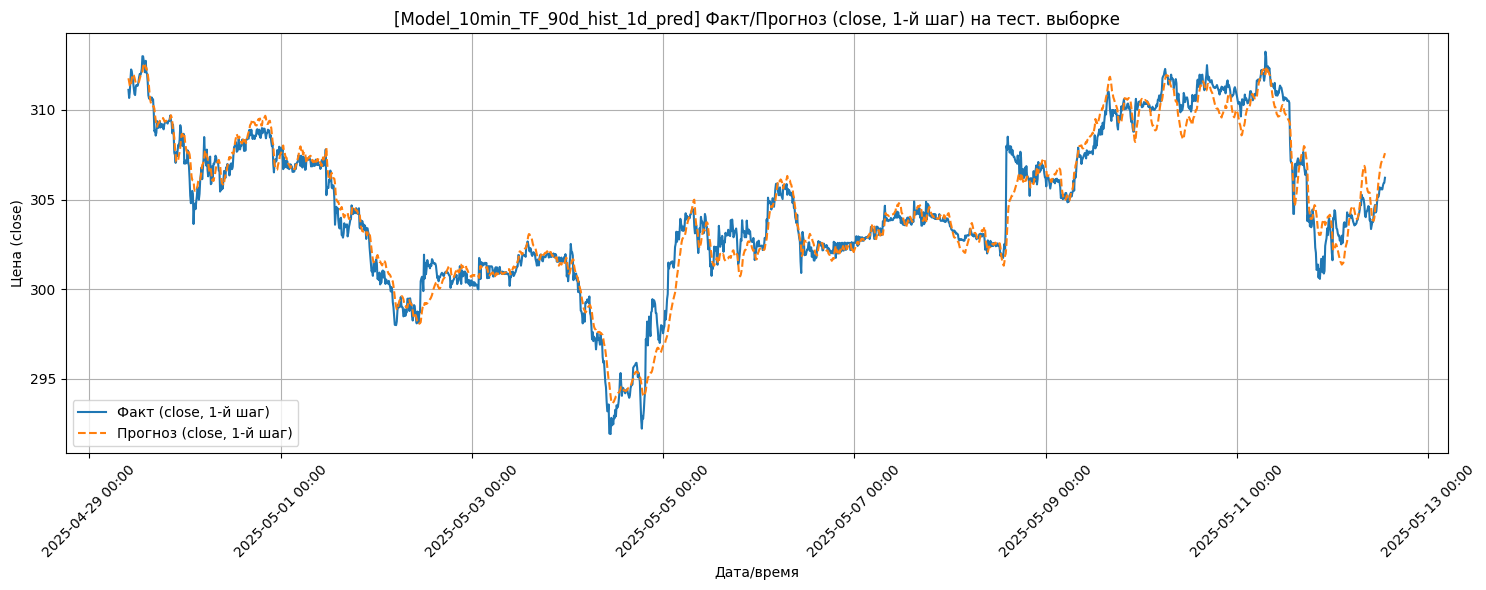

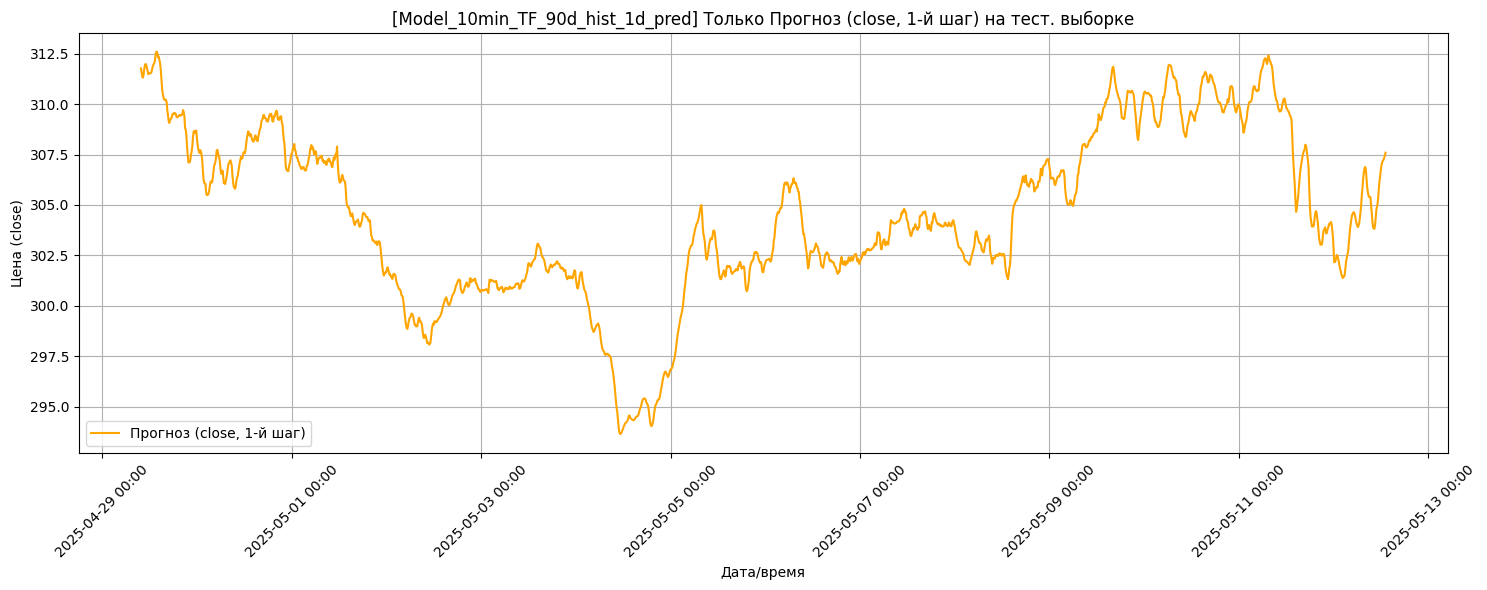


[Model_10min_TF_90d_hist_1d_pred] Средняя MSE по всем 144 шагам (тест): 18.4234

[Model_10min_TF_90d_hist_1d_pred] Реальные и прогнозные значения на тестовой выборке (144-й шаг прогноза):
Первые 5 записей:
                     actual_close_144step  predicted_close_144step
datetime                                                          
2025-04-29 09:50:00                306.08               311.644135
2025-04-29 10:00:00                306.60               311.553223
2025-04-29 10:10:00                306.34               311.424286
2025-04-29 10:20:00                306.21               311.414856
2025-04-29 10:30:00                306.80               311.538177

Последние 5 записей:
                     actual_close_144step  predicted_close_144step
datetime                                                          
2025-05-16 09:10:00                306.86               309.585052
2025-05-16 09:20:00                306.98               309.753906
2025-05-16 09:30:00               

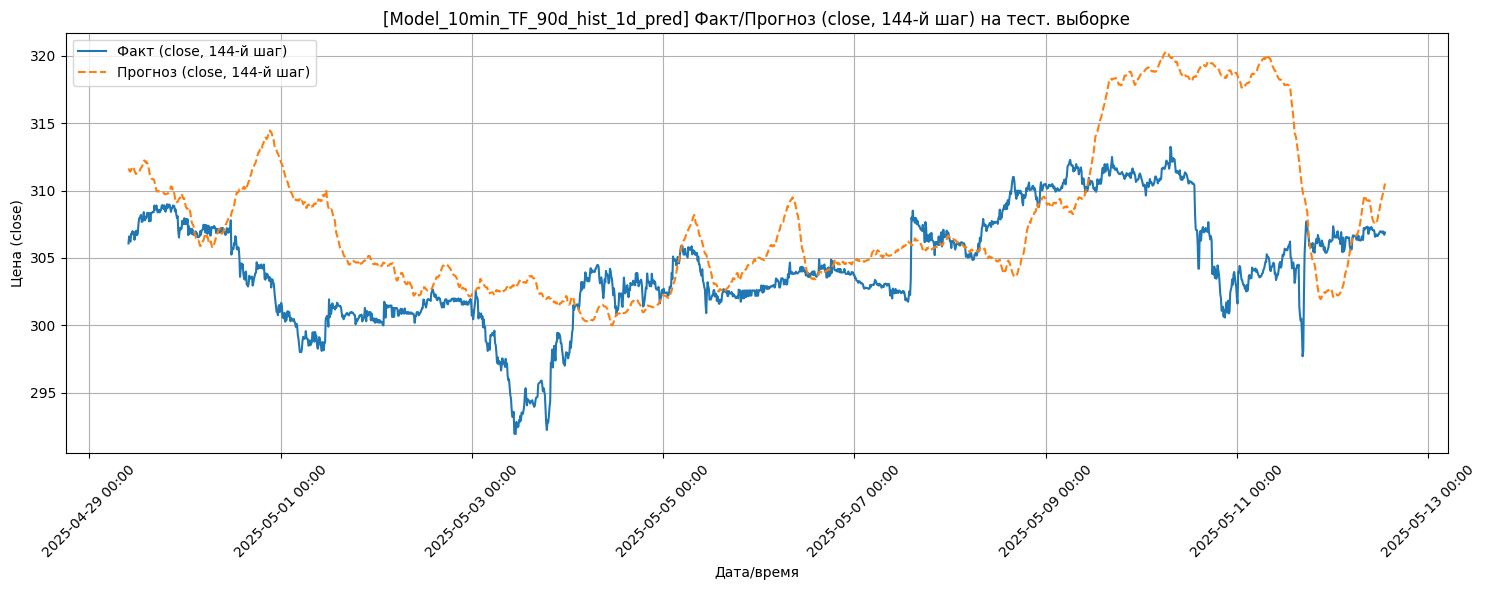

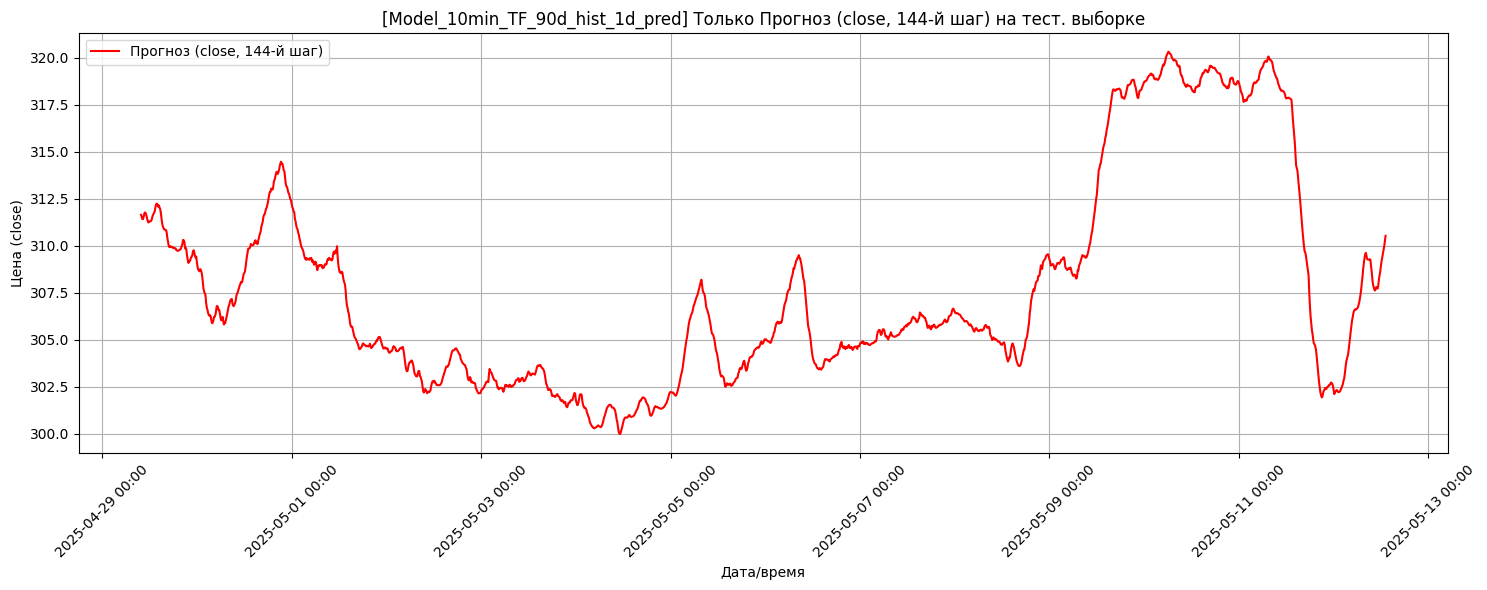


[Model_10min_TF_90d_hist_1d_pred] Рекурсивный прогноз на 144 шагов...
[Model_10min_TF_90d_hist_1d_pred] Рекурсивный прогноз завершен. Предсказано 144 шагов.

[Model_10min_TF_90d_hist_1d_pred] Будущие прогнозные значения (144 из 144 запрошенных шагов):
Первые 5 прогнозов:
                     predicted_value
datetime                            
2025-05-17 12:30:00       307.479401
2025-05-17 12:40:00       307.296631
2025-05-17 12:50:00       307.471222
2025-05-17 13:00:00       307.516052
2025-05-17 13:10:00       307.446503

Последние 5 прогнозов:
                     predicted_value
datetime                            
2025-05-18 11:40:00       311.033539
2025-05-18 11:50:00       311.038147
2025-05-18 12:00:00       310.890808
2025-05-18 12:10:00       310.767609
2025-05-18 12:20:00       310.843567


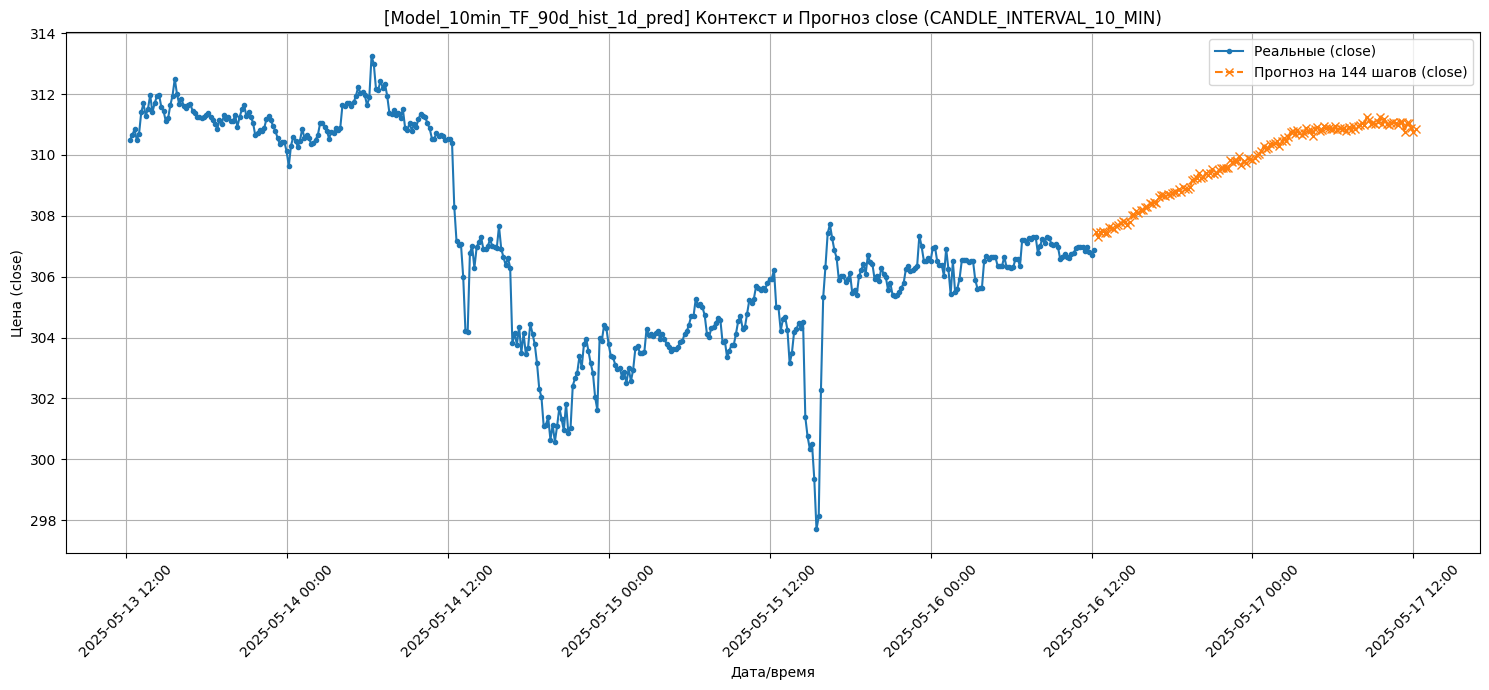

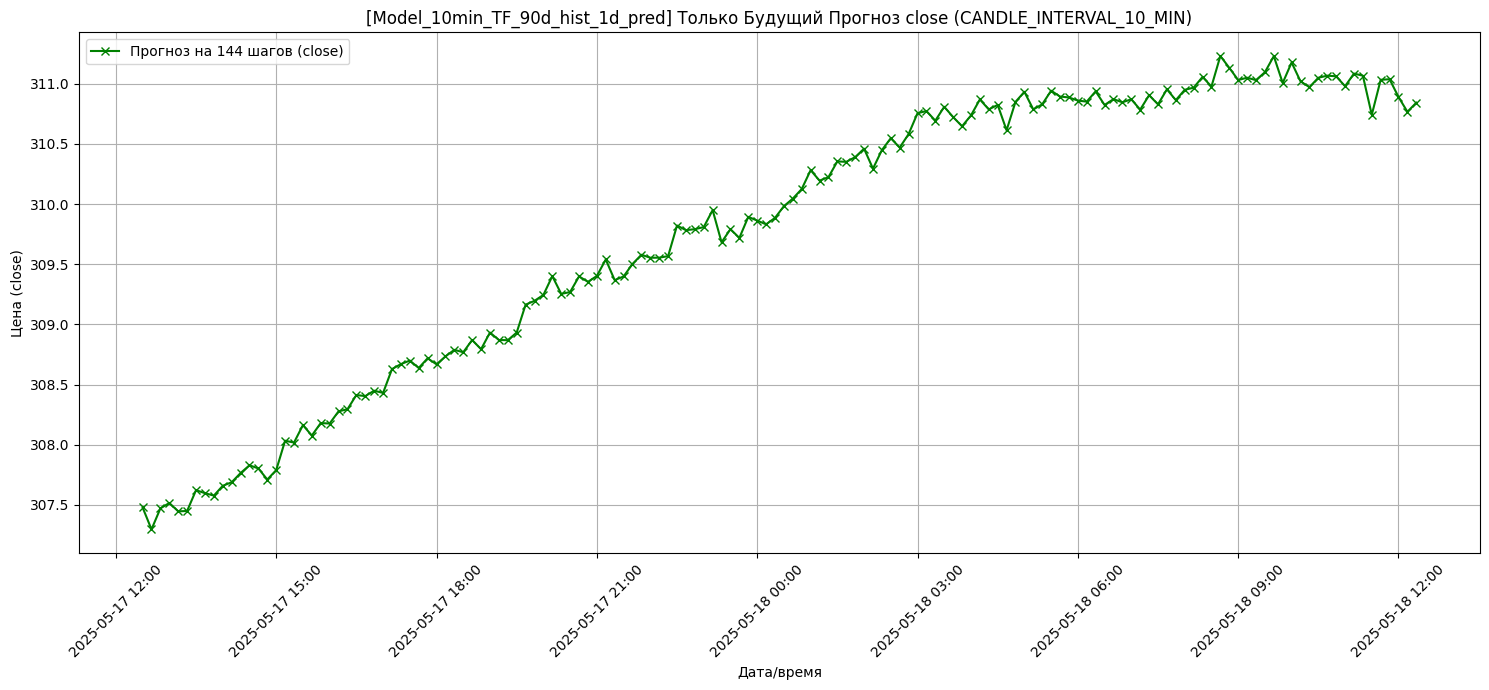


============================== Завершение обработки модели: Model_10min_TF_90d_hist_1d_pred ==============================
[Model_5min_TF_60d_hist_15h_pred] Результаты fold 4 (1-й шаг):
  MSE: 0.9466
  RMSE: 0.9729
  MAE: 0.7053
  R2: 0.9918
  MSE_PCT: 0.0010 %
  RMSE_PCT: 0.3180 %
  MAE_PCT: 0.2305 %
  R2_PCT: 99.1831 %
[Model_5min_TF_60d_hist_15h_pred] Результаты fold 1 (1-й шаг):
  MSE: 1.2386
  RMSE: 1.1129
  MAE: 0.8750
  R2: 0.9896
  MSE_PCT: 0.0013 %
  RMSE_PCT: 0.3637 %
  MAE_PCT: 0.2860 %
  R2_PCT: 98.9610 %
[Model_5min_TF_60d_hist_15h_pred] Результаты fold 2 (1-й шаг):
  MSE: 1.2740
  RMSE: 1.1287
  MAE: 0.7751
  R2: 0.9895
  MSE_PCT: 0.0014 %
  RMSE_PCT: 0.3689 %
  MAE_PCT: 0.2533 %
  R2_PCT: 98.9524 %

--- [Model_5min_TF_60d_hist_15h_pred] CV завершена ---
[Model_5min_TF_60d_hist_15h_pred] Лучшая модель из фолда 3 (MSE: 0.7768)
[Model_5min_TF_60d_hist_15h_pred] Метрики лучшей модели (валид. набор, 1-й шаг):
  MSE: 0.7768
  RMSE: 0.8814
  MAE: 0.6033
  R2: 0.9932
  MSE_PCT:

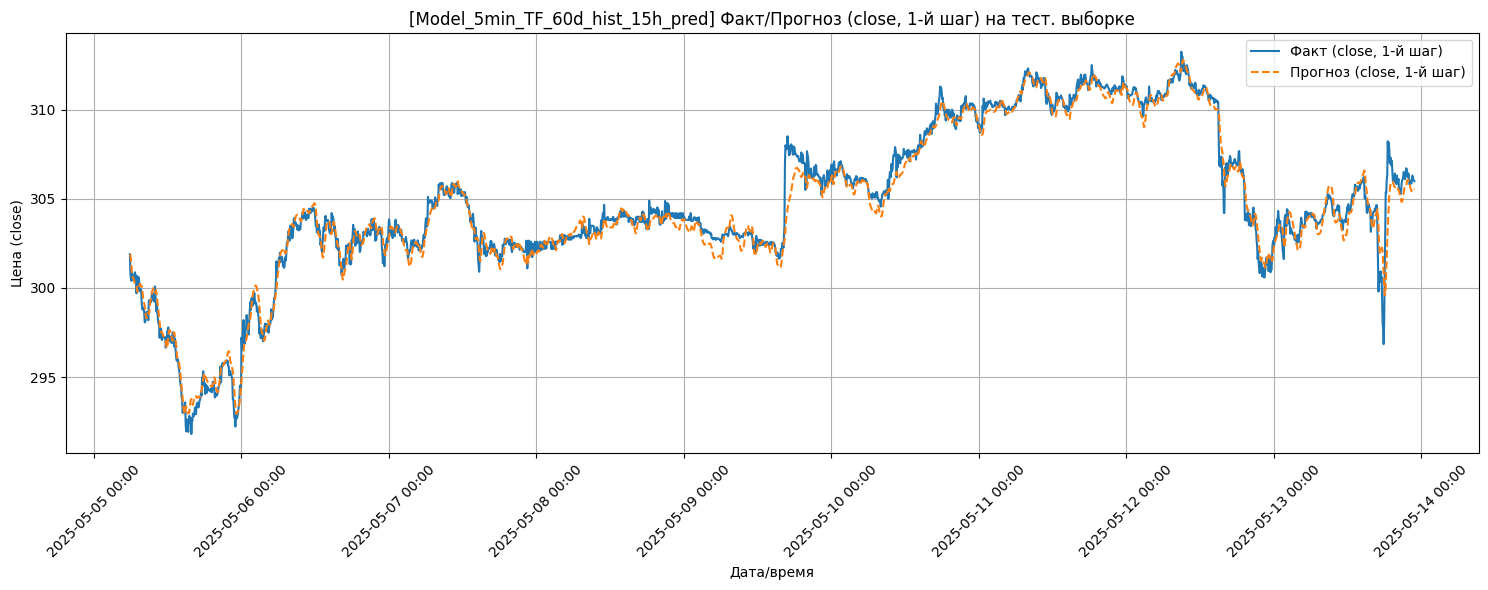

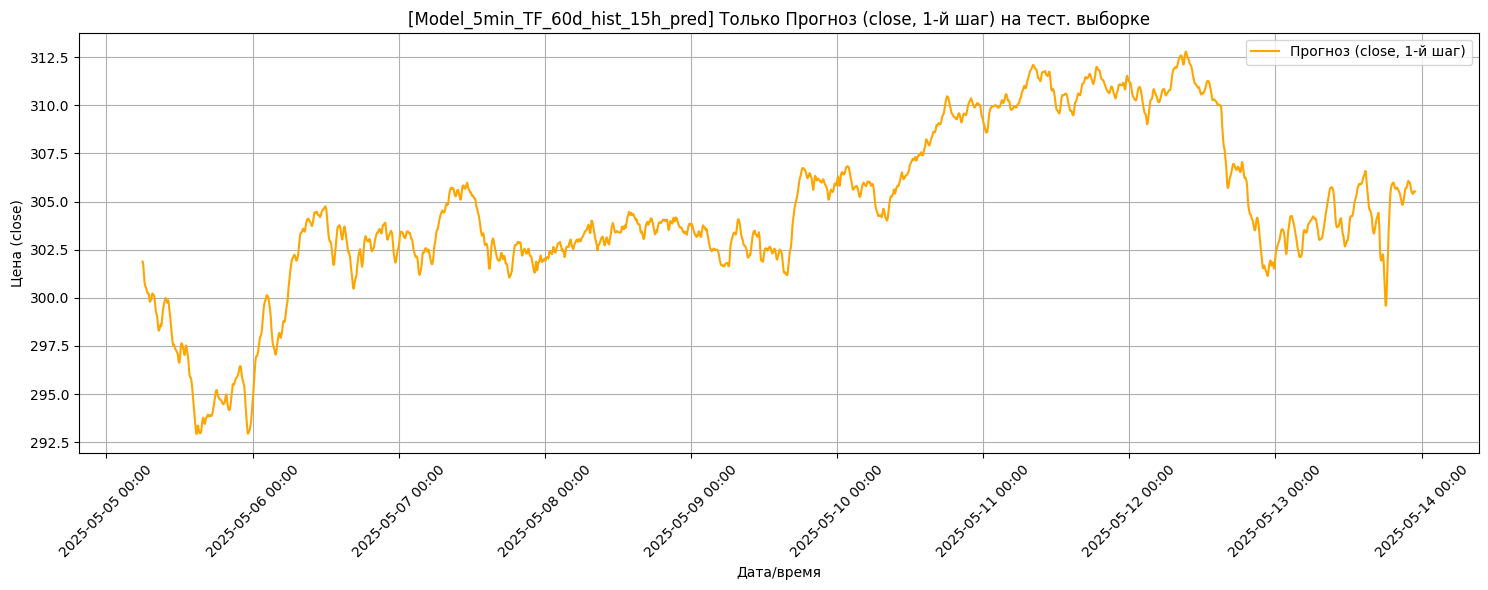


[Model_5min_TF_60d_hist_15h_pred] Средняя MSE по всем 180 шагам (тест): 7.7791

[Model_5min_TF_60d_hist_15h_pred] Реальные и прогнозные значения на тестовой выборке (180-й шаг прогноза):
Первые 5 записей:
                     actual_close_180step  predicted_close_180step
datetime                                                          
2025-05-05 05:55:00                295.36               300.198303
2025-05-05 06:00:00                295.63               300.140228
2025-05-05 06:05:00                295.79               299.934387
2025-05-05 06:10:00                295.69               299.669617
2025-05-05 06:15:00                295.80               299.435425

Последние 5 записей:
                     actual_close_180step  predicted_close_180step
datetime                                                          
2025-05-16 18:05:00                306.81               303.477295
2025-05-16 18:10:00                306.80               303.551361
2025-05-16 18:15:00                

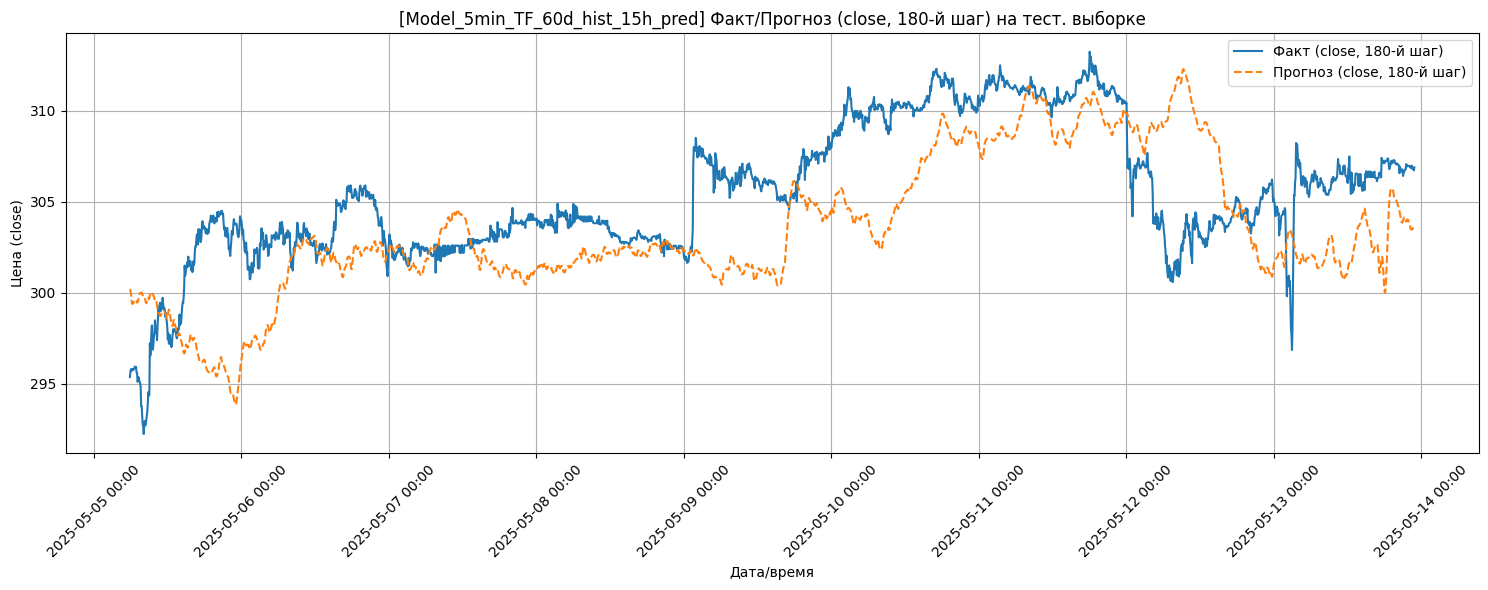

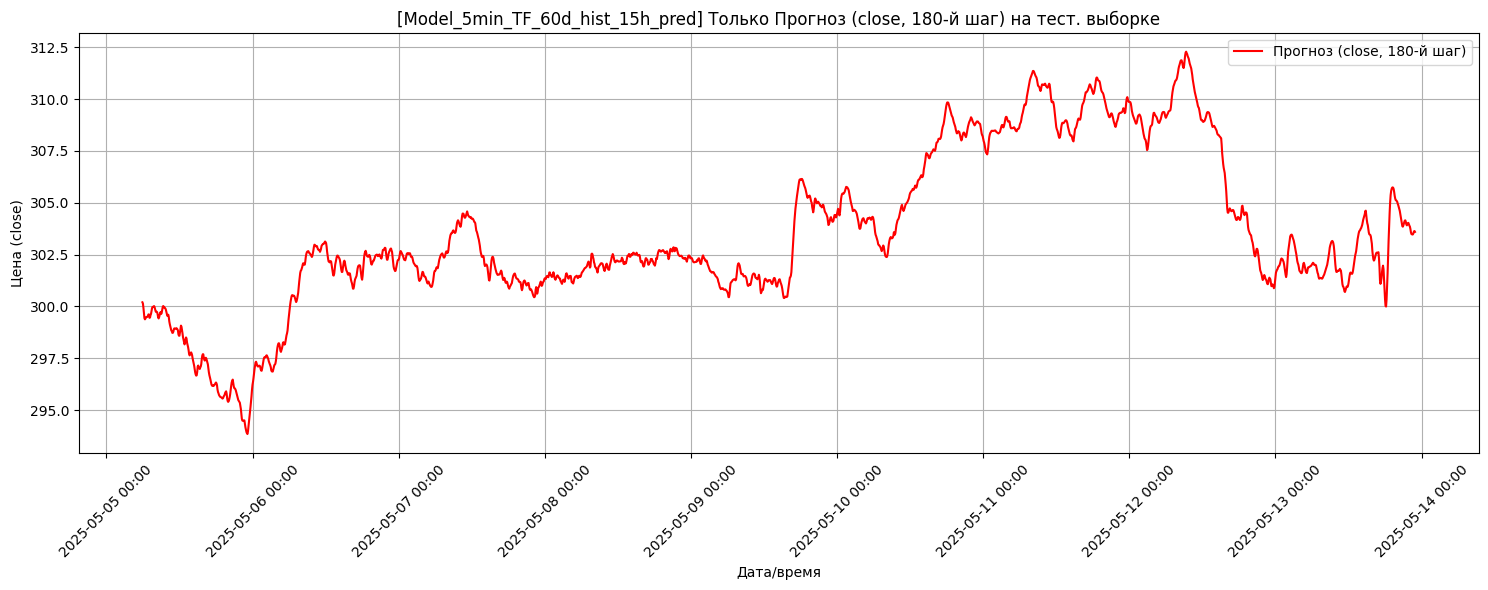


[Model_5min_TF_60d_hist_15h_pred] Рекурсивный прогноз на 180 шагов...
[Model_5min_TF_60d_hist_15h_pred] Рекурсивный прогноз завершен. Предсказано 180 шагов.

[Model_5min_TF_60d_hist_15h_pred] Будущие прогнозные значения (180 из 180 запрошенных шагов):
Первые 5 прогнозов:
                     predicted_value
datetime                            
2025-05-17 12:25:00       306.353607
2025-05-17 12:30:00       306.314880
2025-05-17 12:35:00       306.528351
2025-05-17 12:40:00       306.278809
2025-05-17 12:45:00       306.251434

Последние 5 прогнозов:
                     predicted_value
datetime                            
2025-05-18 03:00:00       304.270020
2025-05-18 03:05:00       304.435852
2025-05-18 03:10:00       304.354767
2025-05-18 03:15:00       304.177795
2025-05-18 03:20:00       304.345673


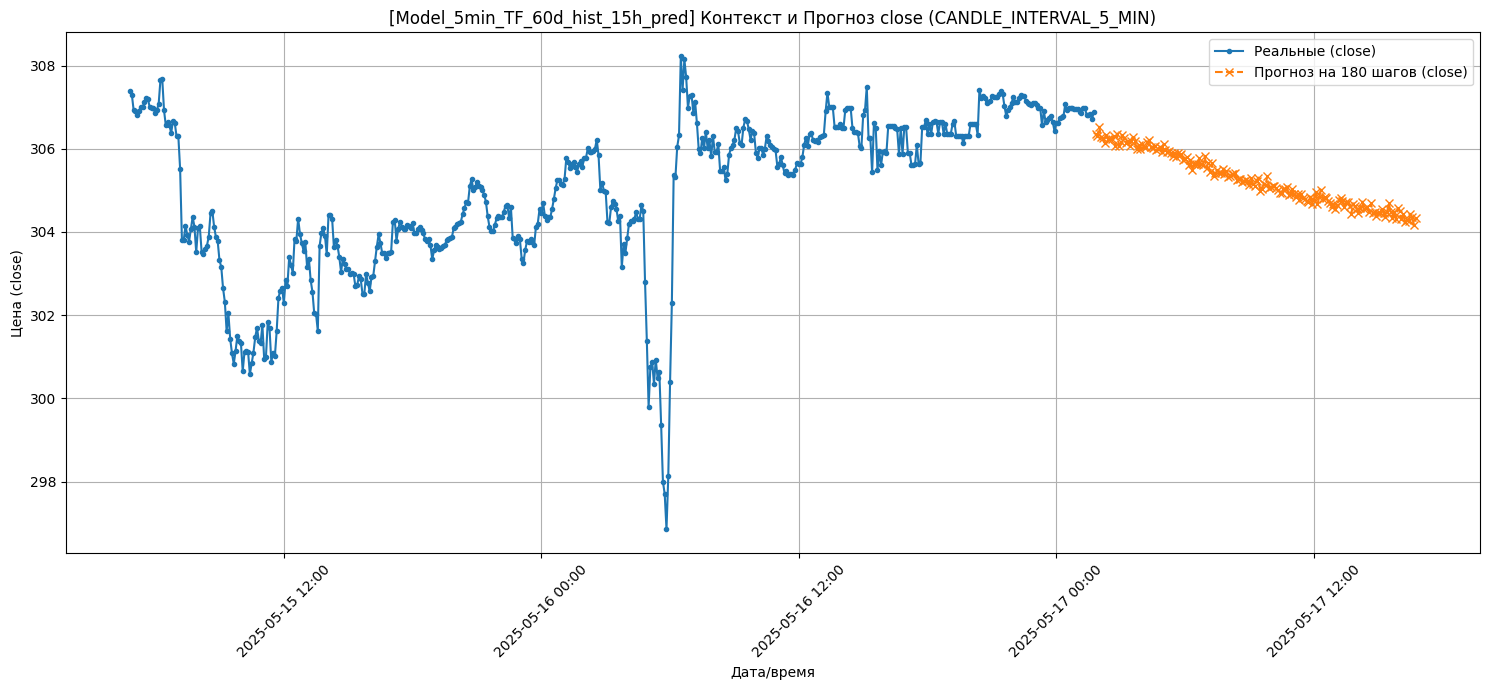

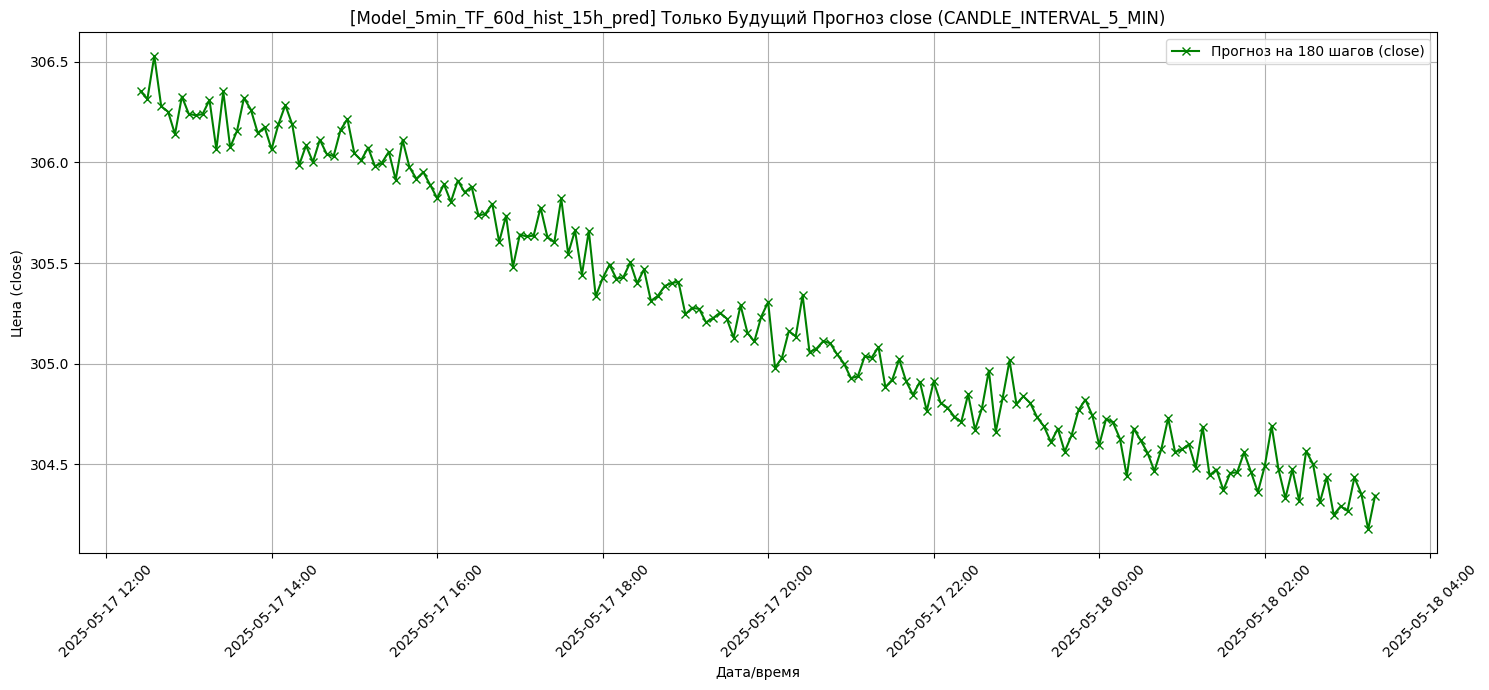


============================== Завершение обработки модели: Model_5min_TF_60d_hist_15h_pred ==============================
[Model_1min_TF_30d_hist_5h_pred] Результаты fold 4 (1-й шаг):
  MSE: 0.0675
  RMSE: 0.2598
  MAE: 0.1887
  R2: 0.9982
  MSE_PCT: 0.0001 %
  RMSE_PCT: 0.0848 %
  MAE_PCT: 0.0615 %
  R2_PCT: 99.8175 %
[Model_1min_TF_30d_hist_5h_pred] Результаты fold 3 (1-й шаг):
  MSE: 0.0637
  RMSE: 0.2523
  MAE: 0.1801
  R2: 0.9983
  MSE_PCT: 0.0001 %
  RMSE_PCT: 0.0823 %
  MAE_PCT: 0.0588 %
  R2_PCT: 99.8327 %

--- [Model_1min_TF_30d_hist_5h_pred] CV завершена ---
[Model_1min_TF_30d_hist_5h_pred] Лучшая модель из фолда 3 (MSE: 0.0637)
[Model_1min_TF_30d_hist_5h_pred] Метрики лучшей модели (валид. набор, 1-й шаг):
  MSE: 0.0637
  RMSE: 0.2523
  MAE: 0.1801
  R2: 0.9983
  MSE_PCT: 0.0001 %
  RMSE_PCT: 0.0823 %
  MAE_PCT: 0.0588 %
  R2_PCT: 99.8327 %

--- [Model_1min_TF_30d_hist_5h_pred] Финальное тестирование ---
[Model_1min_TF_30d_hist_5h_pred] Метрики на тест. выборке (1-й шаг):


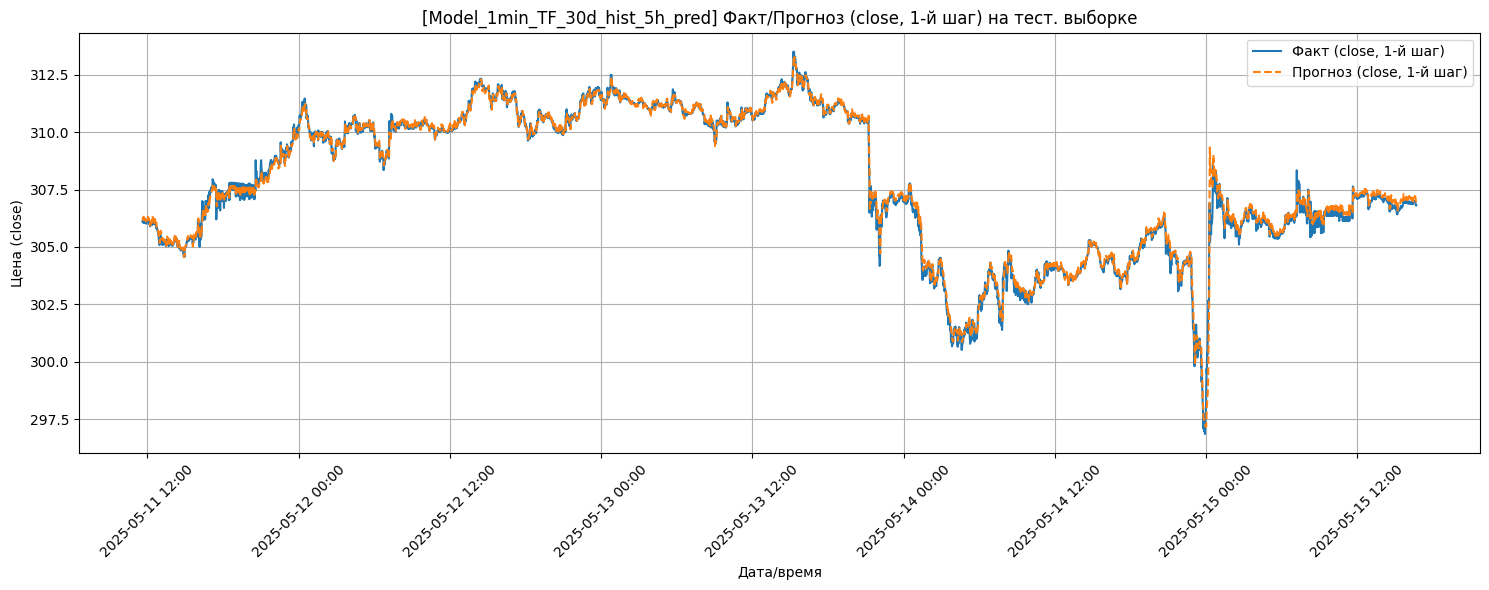

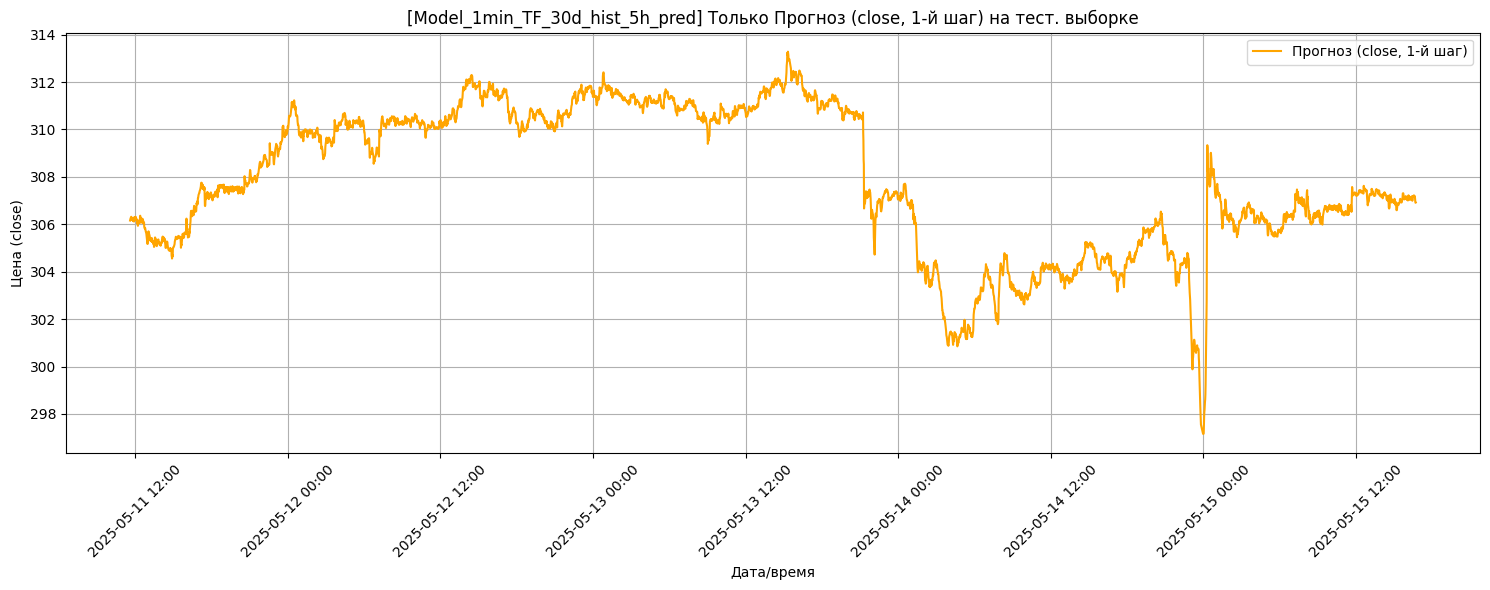


[Model_1min_TF_30d_hist_5h_pred] Средняя MSE по всем 15 шагам (тест): 0.2516

[Model_1min_TF_30d_hist_5h_pred] Реальные и прогнозные значения на тестовой выборке (15-й шаг прогноза):
Первые 5 записей:
                     actual_close_15step  predicted_close_15step
datetime                                                        
2025-05-11 11:37:00               306.06              306.177002
2025-05-11 11:38:00               306.07              306.218445
2025-05-11 11:39:00               306.03              306.248718
2025-05-11 11:40:00               306.06              306.276917
2025-05-11 11:41:00               306.02              306.281036

Последние 5 записей:
                     actual_close_15step  predicted_close_15step
datetime                                                        
2025-05-17 12:02:00               306.72              307.151947
2025-05-17 12:03:00               306.83              307.080078
2025-05-17 12:04:00               306.74              306.960

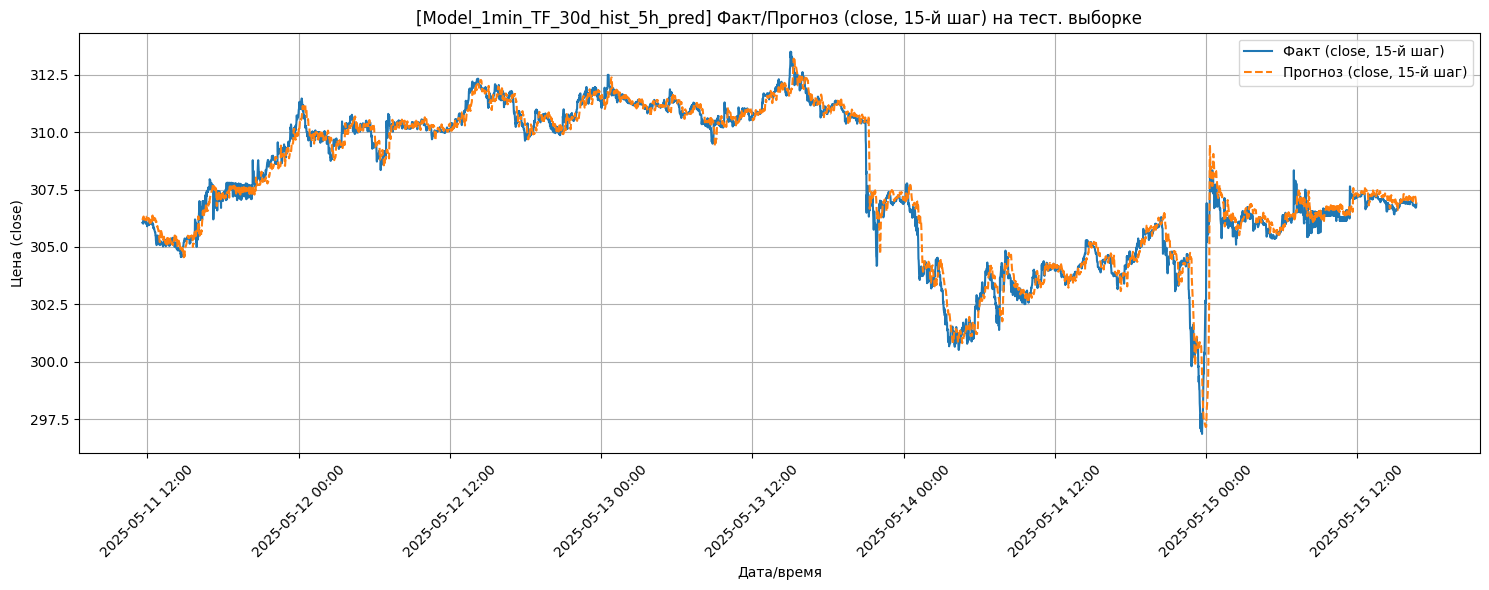

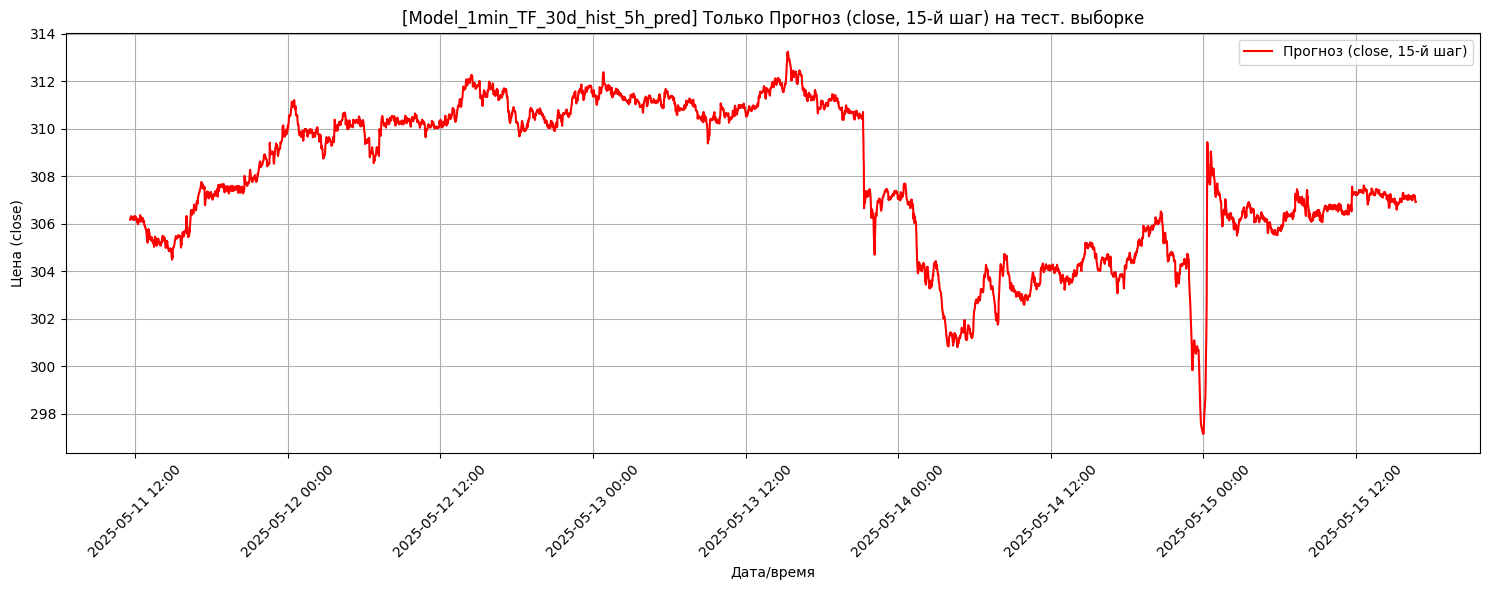


[Model_1min_TF_30d_hist_5h_pred] Рекурсивный прогноз на 300 шагов...
[Model_1min_TF_30d_hist_5h_pred] Ошибка predict_future: мало данных после ТА (85). Прогноз остановлен.
[Model_1min_TF_30d_hist_5h_pred] Рекурсивный прогноз завершен. Предсказано 15 шагов.

[Model_1min_TF_30d_hist_5h_pred] Будущие прогнозные значения (15 из 300 запрошенных шагов):
Первые 5 прогнозов:
                     predicted_value
datetime                            
2025-05-17 12:21:00       307.139160
2025-05-17 12:22:00       307.084747
2025-05-17 12:23:00       307.134277
2025-05-17 12:24:00       307.120209
2025-05-17 12:25:00       307.147247

Последние 5 прогнозов:
                     predicted_value
datetime                            
2025-05-17 12:31:00       307.140350
2025-05-17 12:32:00       307.141418
2025-05-17 12:33:00       307.114563
2025-05-17 12:34:00       307.128113
2025-05-17 12:35:00       307.137878


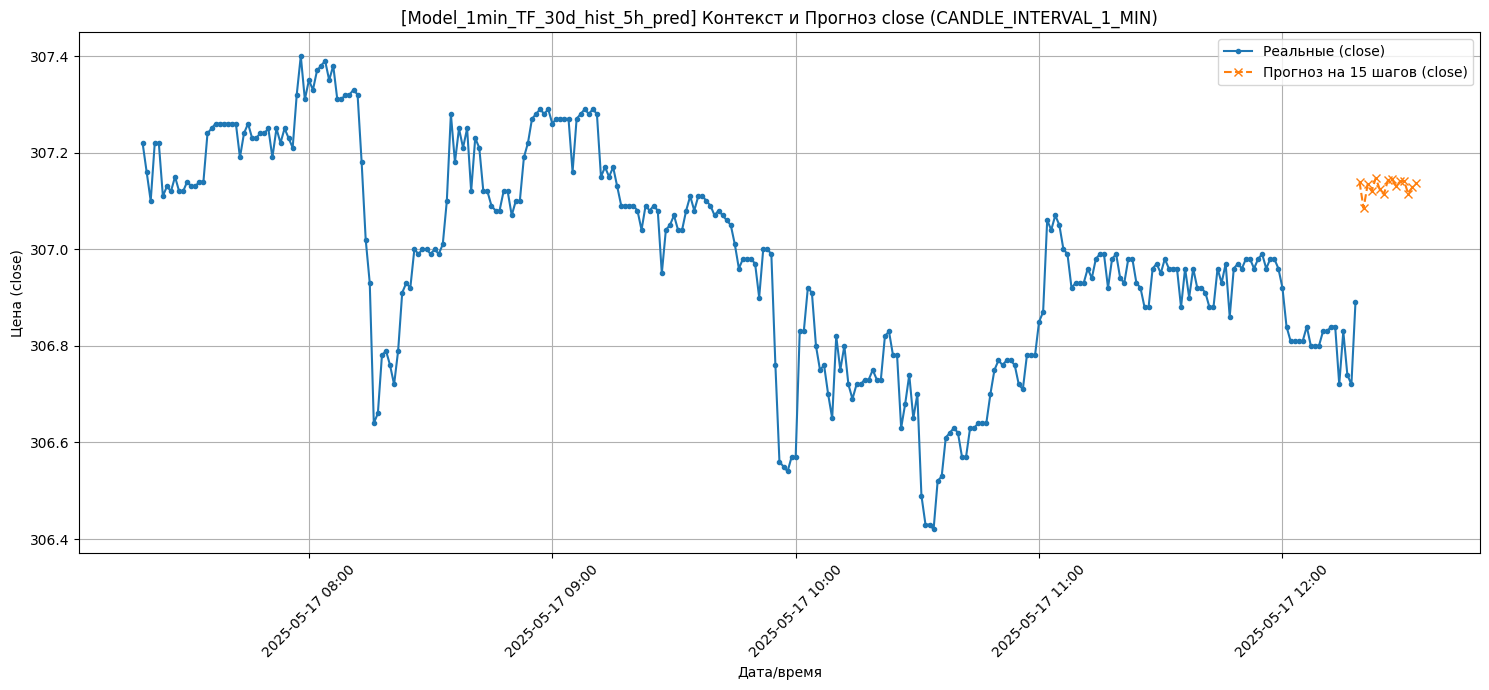

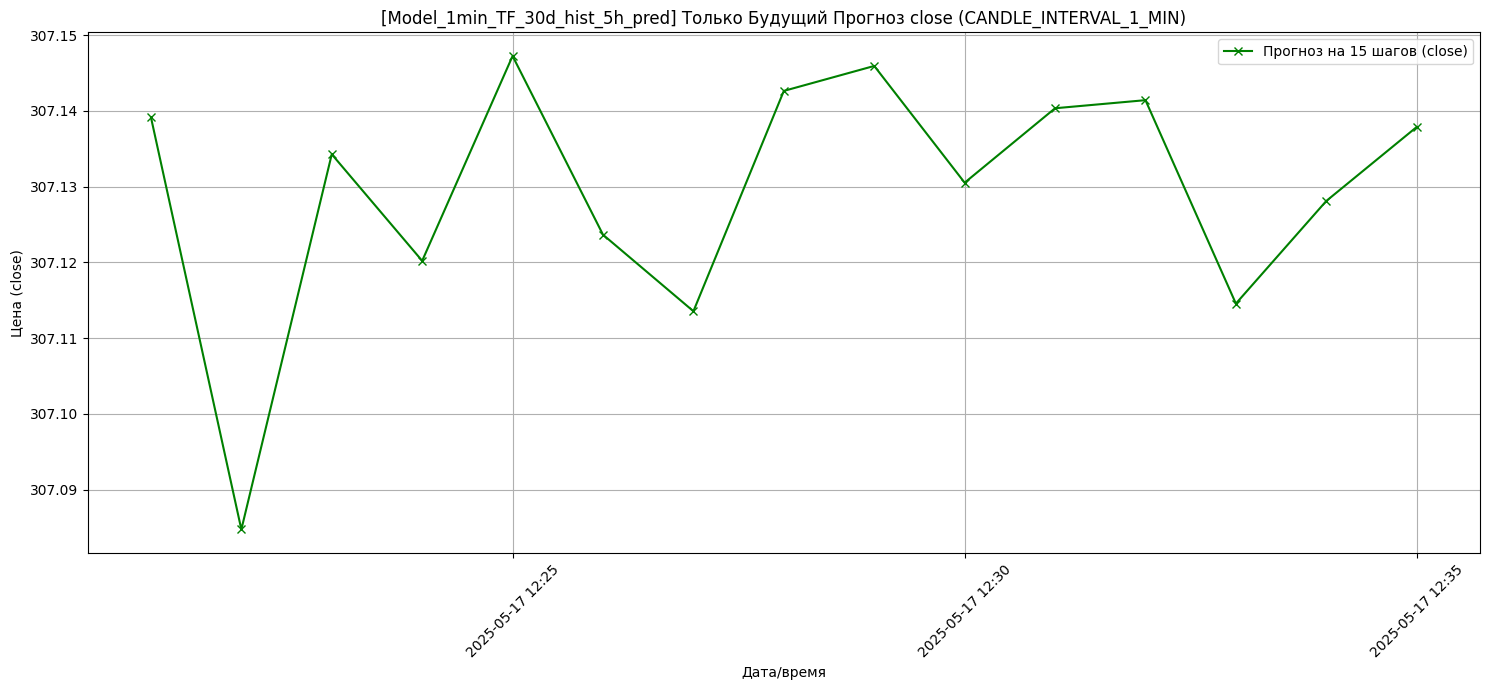


============================== Завершение обработки модели: Model_1min_TF_30d_hist_5h_pred ==============================

--- Работа всей программы завершена ---


In [35]:

if __name__ == "__main__":

    BASE_DAYS_HISTORY = 30
    BASE_CANDLE_TIMEFRAME = CandleInterval.CANDLE_INTERVAL_1_MIN
    BASE_N_STEPS_IN = 150
    BASE_N_STEPS_OUT = 15
    BASE_FUTURE_PREDICTIONS_COUNT = 300

    model_configs = [
        {
            "name": "Model_1min_TF_30d_hist_5h_pred",
            "days_history": BASE_DAYS_HISTORY,
            "candle_timeframe": BASE_CANDLE_TIMEFRAME,
            "n_steps_in": BASE_N_STEPS_IN,
            "n_steps_out": BASE_N_STEPS_OUT,
            "future_predictions": BASE_FUTURE_PREDICTIONS_COUNT
        },
        {
            "name": "Model_5min_TF_60d_hist_15h_pred",
            "days_history": 60,
            "candle_timeframe": CandleInterval.CANDLE_INTERVAL_5_MIN,
            "n_steps_out": (15 * 60) // 5,
            "n_steps_in": int(((15 * 60) // 5) * 1.5),
            "future_predictions": (15 * 60) // 5
        },
        {
            "name": "Model_10min_TF_90d_hist_1d_pred",
            "days_history": 90,
            "candle_timeframe": CandleInterval.CANDLE_INTERVAL_10_MIN,
            "n_steps_out": (24 * 60) // 10,
            "n_steps_in": int(((24 * 60) // 10) * 1.5),
            "future_predictions": (24 * 60) // 10
        }
    ]

    MIN_DESIRED_WORKERS = 12
    cpu_cores = os.cpu_count()
    if cpu_cores is None:
        print(
            f"Предупреждение: Не удалось определить количество CPU ядер. Будет использовано до {MIN_DESIRED_WORKERS} потоков для моделей.")
        max_cpu_based_workers = MIN_DESIRED_WORKERS
    else:
        max_cpu_based_workers = cpu_cores
        print(f"Обнаружено {cpu_cores} CPU ядер.")

    effective_workers = min(len(model_configs), max_cpu_based_workers)
    MAX_MODEL_WORKERS = min(effective_workers, MIN_DESIRED_WORKERS) if MIN_DESIRED_WORKERS > 0 else effective_workers
    MAX_MODEL_WORKERS = max(1, MAX_MODEL_WORKERS) if len(model_configs) > 0 else 0

    print(f"INFO: Запуск обучения для {len(model_configs)} моделей.")
    print(f"INFO: Запрошено до {MIN_DESIRED_WORKERS} потоков для моделей (если MIN_DESIRED_WORKERS > 0).")
    print(f"INFO: Максимальное количество одновременно обучаемых моделей (MAX_MODEL_WORKERS): {MAX_MODEL_WORKERS}")
    if MAX_MODEL_WORKERS > 1:
        print(
            "INFO: Если используется GPU, УБЕДИТЕСЬ, что TensorFlow настроен для роста памяти GPU (memory growth), иначе установите меньшее значение MAX_MODEL_WORKERS (например, 1).")
        print(
            "INFO: В противном случае TensorFlow может занять всю память GPU на первой модели, и остальные не запустятся.")

    if len(model_configs) > 0 and MAX_MODEL_WORKERS > 0:
        with ThreadPoolExecutor(max_workers=MAX_MODEL_WORKERS) as executor:
            futures = [executor.submit(run_model_pipeline, config) for config in model_configs]
            for i, future in enumerate(as_completed(futures)):
                try:
                    future.result()
                except Exception as e:
                    with print_lock:
                        print(
                            f"КРИТИЧЕСКАЯ ОШИБКА (поток для модели {model_configs[i]['name'] if i < len(model_configs) else 'unknown'}): Обучение завершилось с исключением на верхнем уровне: {e}")
                        import traceback

                        print(traceback.format_exc())
    elif len(model_configs) == 0:
        print("INFO: Нет конфигураций моделей для обучения.")
    else:
        print(
            f"INFO: MAX_MODEL_WORKERS ({MAX_MODEL_WORKERS}) или количество моделей ({len(model_configs)}) равно 0, обучение не будет запущено.")

    with print_lock:
        print("\n--- Работа всей программы завершена ---")